In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter('ignore')

LOAD THE DATA

In [2]:
df = pd.read_csv(r"C:\Users\Kishore\Downloads\ecommerce_returns.csv")
df

,Order_ID,Order_Date,Customer_ID,Product_ID,Category,Supplier_ID,Region,State,Marketing_Channel,Payment_Method,Shipping_Method,Quantity,Unit_Price,Discount_Rate,Order_Value,Delivery_Days,Customer_Rating,Return_Status,Return_Days_After_Delivery,Return_Reason
0,ORD0000001,2024-09-16,CUS002988,PRD00532,Beauty,SUP022,Central,Chhattisgarh,Organic Search,UPI,Express,1,821.38,0.3820,507.62,6.0,4.0,Not Returned,NaN,NaN
1,ORD0000002,2025-02-13,CUS018203,PRD01000,Fashion,SUP010,Central,Madhya Pradesh,Direct,Credit Card,Standard,1,3845.71,0.4601,2076.14,5.0,4.0,Not Returned,NaN,NaN
2,ORD0000003,2024-10-07,CUS008369,PRD01056,Sports,SUP006,East,Jharkhand,Email,UPI,Standard,3,723.29,0.1943,1748.17,2.0,4.0,Not Returned,NaN,NaN
3,ORD0000004,2025-04-24,CUS000909,PRD02226,Beauty,SUP006,South,Tamil Nadu,Affiliate,Debit Card,Standard,1,470.36,0.1881,381.88,3.0,5.0,Not Returned,NaN,NaN
4,ORD0000005,2026-06-25,CUS013865,PRD00156,Electronics,SUP006,West,Gujarat,Social Media,Cash on Delivery,Standard,2,11538.03,0.1736,19070.03,4.0,4.0,Not Returned,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100065,ORD0019454,2025-08-16,CUS028244,PRD02276,Electronics,SUP026,Central,Chhattisgarh,Paid Search,UPI,Standard,1,11382.21,0.2722,8283.94,3.0,4.0,Not Returned,NaN,NaN
100066,ORD0003762,2024-05-02,CUS002680,PRD01636,Fashion,SUP016,South,Andhra Pradesh,Organic Search,Debit Card,Standard,1,1291.29,0.2103,1019.79,6.0,3.0,Not Returned,NaN,NaN
100067,ORD0046857,2024-04-26,CUS012550,PRD01145,Fashion,SUP005,South,Telangana,Paid Search,UPI,Same Day,2,1360.81,0.1205,2393.57,5.0,2.0,Returned,12.0,Changed Mind
100068,ORD0057527,2025-05-30,CUS014063,PRD02073,Sports,SUP003,West,Goa,Affiliate,Credit Card,Express,1,3176.36,0.2182,2483.37,4.0,3.0,Not Returned,NaN,NaN


In [3]:
df.shape

(100070, 20)

In [4]:
df.dtypes

Order_ID                          str
Order_Date                        str
Customer_ID                       str
Product_ID                        str
Category                          str
Supplier_ID                       str
Region                            str
State                             str
Marketing_Channel                 str
Payment_Method                    str
Shipping_Method                   str
Quantity                        int64
Unit_Price                    float64
Discount_Rate                 float64
Order_Value                   float64
Delivery_Days                 float64
Customer_Rating               float64
Return_Status                     str
Return_Days_After_Delivery    float64
Return_Reason                     str
dtype: object

In [5]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100070 entries, 0 to 100069
Data columns (total 20 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   Order_ID                    100070 non-null  str           
 1   Order_Date                  100070 non-null  datetime64[us]
 2   Customer_ID                 100070 non-null  str           
 3   Product_ID                  100070 non-null  str           
 4   Category                    100070 non-null  str           
 5   Supplier_ID                 100070 non-null  str           
 6   Region                      100070 non-null  str           
 7   State                       100070 non-null  str           
 8   Marketing_Channel           99870 non-null   str           
 9   Payment_Method              100070 non-null  str           
 10  Shipping_Method             100070 non-null  str           
 11  Quantity                    100070 non-null  int64

In [7]:
df.isnull().sum()

Order_ID                          0
Order_Date                        0
Customer_ID                       0
Product_ID                        0
Category                          0
Supplier_ID                       0
Region                            0
State                             0
Marketing_Channel               200
Payment_Method                    0
Shipping_Method                   0
Quantity                          0
Unit_Price                        0
Discount_Rate                     0
Order_Value                       0
Delivery_Days                   300
Customer_Rating                 801
Return_Status                     0
Return_Days_After_Delivery    86011
Return_Reason                 86011
dtype: int64

In [8]:
df.describe()

,Order_Date,Quantity,Unit_Price,Discount_Rate,Order_Value,Delivery_Days,Customer_Rating,Return_Days_After_Delivery
count,100070,100070.000000,100070.000000,100070.000000,100070.000000,99770.000000,99269.000000,14059.000000
mean,2025-05-12 09:42:17.303887,1.379364,3449.589541,0.199704,3826.812963,4.588824,3.864127,15.541504
min,2024-01-01 00:00:00,1.000000,66.810000,0.000800,46.820000,1.000000,1.000000,1.000000
25%,2024-09-05 00:00:00,1.000000,990.612500,0.107400,920.200000,3.000000,3.000000,8.000000
50%,2025-05-12 00:00:00,1.000000,1853.695000,0.179500,1836.960000,5.000000,4.000000,15.000000
75%,2026-01-17 00:00:00,2.000000,4016.820000,0.272400,4376.890000,6.000000,5.000000,23.000000
max,2026-09-26 00:00:00,4.000000,62680.720000,0.650000,105351.200000,15.000000,5.000000,30.000000
std,NaN,0.688146,4116.157103,0.120335,5532.193690,2.116455,0.871986,8.622844


In [9]:
# Categorical Missing Value Investigation

categorical_columns = [
    "Category",
    "Supplier_ID",
    "Region",
    "State",
    "Marketing_Channel",
    "Payment_Method",
    "Shipping_Method",
    "Return_Status",
    "Return_Reason"
]

for col in categorical_columns:

    print("\nColumn:", col)

    print(
        "Missing:",
        df[col].isna().sum()
    )

    print(
        "Unique values:",
        df[col].nunique()
    )

    print(
        df[col].value_counts(dropna=False).head(10)
    )


Column: Category
Missing: 0
Unique values: 12
Category
Fashion            27813
Electronics        21872
Home & Kitchen     18248
Beauty             12071
Sports             11843
Books               8043
Fashion               54
Electronics           39
Home & Kitchen        27
Sports                22
Name: count, dtype: int64

Column: Supplier_ID
Missing: 0
Unique values: 30
Supplier_ID
SUP024    3491
SUP006    3428
SUP003    3419
SUP009    3381
SUP002    3376
SUP004    3372
SUP007    3371
SUP005    3365
SUP015    3356
SUP025    3356
Name: count, dtype: int64

Column: Region
Missing: 0
Unique values: 10
Region
South      28105
West       21739
North      20075
Central    15063
East       14968
south         29
west          25
north         23
east          23
central       20
Name: count, dtype: int64

Column: State
Missing: 0
Unique values: 19
State
Chhattisgarh      7620
Madhya Pradesh    7463
Karnataka         5694
Andhra Pradesh    5647
Telangana         5623
Kerala           

In [10]:
df['Delivery_Days'] = df['Delivery_Days'].fillna(df['Delivery_Days'].median())


In [11]:
df['Customer_Rating'] = df['Customer_Rating'].fillna(df['Customer_Rating'].median())

In [12]:
df['Return_Days_After_Delivery'] = df['Return_Days_After_Delivery'].fillna(df['Return_Days_After_Delivery'].median())

In [13]:
df["Marketing_Channel"] = df["Marketing_Channel"].fillna("Unknown")

In [14]:
print(df["Return_Days_After_Delivery"].isna().sum())
print(df.groupby("Return_Status")["Return_Days_After_Delivery"].apply(lambda s: s.isna().sum()))

0
Return_Status
Not Returned    0
Returned        0
Name: Return_Days_After_Delivery, dtype: int64


In [15]:
df.isnull().sum()

Order_ID                          0
Order_Date                        0
Customer_ID                       0
Product_ID                        0
Category                          0
Supplier_ID                       0
Region                            0
State                             0
Marketing_Channel                 0
Payment_Method                    0
Shipping_Method                   0
Quantity                          0
Unit_Price                        0
Discount_Rate                     0
Order_Value                       0
Delivery_Days                     0
Customer_Rating                   0
Return_Status                     0
Return_Days_After_Delivery        0
Return_Reason                 86011
dtype: int64

In [16]:
df.duplicated().sum()

np.int64(70)

In [17]:
df=df.drop_duplicates()

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
for col in ["Category", "Region", "State", "Marketing_Channel",
            "Payment_Method", "Shipping_Method", "Return_Reason"]:
    df[col] = df[col].str.strip().str.title()

In [20]:
df.head(200)

,Order_ID,Order_Date,Customer_ID,Product_ID,Category,Supplier_ID,Region,State,Marketing_Channel,Payment_Method,Shipping_Method,Quantity,Unit_Price,Discount_Rate,Order_Value,Delivery_Days,Customer_Rating,Return_Status,Return_Days_After_Delivery,Return_Reason
0,ORD0000001,2024-09-16,CUS002988,PRD00532,Beauty,SUP022,Central,Chhattisgarh,Organic Search,Upi,Express,1,821.38,0.3820,507.62,6.0,4.0,Not Returned,15.0,NaN
1,ORD0000002,2025-02-13,CUS018203,PRD01000,Fashion,SUP010,Central,Madhya Pradesh,Direct,Credit Card,Standard,1,3845.71,0.4601,2076.14,5.0,4.0,Not Returned,15.0,NaN
2,ORD0000003,2024-10-07,CUS008369,PRD01056,Sports,SUP006,East,Jharkhand,Email,Upi,Standard,3,723.29,0.1943,1748.17,2.0,4.0,Not Returned,15.0,NaN
3,ORD0000004,2025-04-24,CUS000909,PRD02226,Beauty,SUP006,South,Tamil Nadu,Affiliate,Debit Card,Standard,1,470.36,0.1881,381.88,3.0,5.0,Not Returned,15.0,NaN
4,ORD0000005,2026-06-25,CUS013865,PRD00156,Electronics,SUP006,West,Gujarat,Social Media,Cash On Delivery,Standard,2,11538.03,0.1736,19070.03,4.0,4.0,Not Returned,15.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,ORD0000196,2024-02-16,CUS003656,PRD00354,Electronics,SUP024,Central,Madhya Pradesh,Email,Debit Card,Standard,1,6060.90,0.1871,4926.86,6.0,1.0,Not Returned,15.0,NaN
196,ORD0000197,2026-05-06,CUS013416,PRD01201,Home & Kitchen,SUP001,South,Tamil Nadu,Email,Debit Card,Standard,1,2548.11,0.3441,1671.40,4.0,5.0,Not Returned,15.0,NaN
197,ORD0000198,2026-06-09,CUS019064,PRD02474,Sports,SUP014,South,Tamil Nadu,Paid Search,Upi,Standard,1,2424.71,0.2638,1784.97,6.0,3.0,Not Returned,15.0,NaN
198,ORD0000199,2026-06-06,CUS004575,PRD02268,Electronics,SUP018,South,Andhra Pradesh,Direct,Upi,Express,1,4623.59,0.1477,3940.64,6.0,3.0,Not Returned,15.0,NaN


In [21]:
df.shape

(100000, 20)

In [22]:
df.isnull().sum()

Order_ID                          0
Order_Date                        0
Customer_ID                       0
Product_ID                        0
Category                          0
Supplier_ID                       0
Region                            0
State                             0
Marketing_Channel                 0
Payment_Method                    0
Shipping_Method                   0
Quantity                          0
Unit_Price                        0
Discount_Rate                     0
Order_Value                       0
Delivery_Days                     0
Customer_Rating                   0
Return_Status                     0
Return_Days_After_Delivery        0
Return_Reason                 85953
dtype: int64

In [23]:
print(df["Return_Status"].value_counts())

print("\nReturn Percentage:")
print(
    df["Return_Status"]
    .value_counts(normalize=True) * 100
)

Return_Status
Not Returned    85953
Returned        14047
Name: count, dtype: int64

Return Percentage:
Return_Status
Not Returned    85.953
Returned        14.047
Name: proportion, dtype: float64


In [24]:
print(
    pd.crosstab(
        df["Return_Status"],
        df["Return_Reason"].isnull(),
        margins=True
    )
)

Return_Reason  False   True     All
Return_Status                      
Not Returned       0  85953   85953
Returned       14047      0   14047
All            14047  85953  100000


In [25]:
print(
    df.groupby("Return_Status")[
        "Return_Days_After_Delivery"
    ].describe()
)

                 count       mean      std   min   25%   50%   75%   max
Return_Status                                                           
Not Returned   85953.0  15.000000  0.00000  15.0  15.0  15.0  15.0  15.0
Returned       14047.0  15.541397  8.62081   1.0   8.0  15.0  23.0  30.0


In [26]:
print("Full duplicate rows:", df.duplicated().sum())

print("Duplicate Order IDs:", df["Order_ID"].duplicated().sum())

Full duplicate rows: 0
Duplicate Order IDs: 0


In [27]:
print("Invalid Quantity:",
      (df["Quantity"] <= 0).sum())

print("Invalid Unit Price:",
      (df["Unit_Price"] <= 0).sum())

print("Invalid Discount:",
      (~df["Discount_Rate"].between(0, 1)).sum())

print("Invalid Rating:",
      (~df["Customer_Rating"].between(1, 5)).sum())

print("Invalid Delivery Days:",
      (df["Delivery_Days"] < 0).sum())

Invalid Quantity: 0
Invalid Unit Price: 0
Invalid Discount: 0
Invalid Rating: 0
Invalid Delivery Days: 0


In [28]:
df["Calculated_Order_Value"] = (
    df["Unit_Price"] *
    df["Quantity"] *
    (1 - df["Discount_Rate"])
)

df["Value_Difference"] = (
    df["Order_Value"] -
    df["Calculated_Order_Value"]
).abs()

print(
    "Order value mismatches:",
    (df["Value_Difference"] > 0.02).sum()
)

Order value mismatches: 74418


In [29]:
df["Calculated_Order_Value"] = (
    df["Unit_Price"] *
    df["Quantity"] *
    (1 - df["Discount_Rate"])
).round(2)

df["Value_Difference"] = (
    df["Order_Value"] -
    df["Calculated_Order_Value"]
).abs()

print("Difference statistics:")
print(df["Value_Difference"].describe())

for threshold in [0.02, 0.05, 0.10, 1, 5]:
    count = (df["Value_Difference"] > threshold).sum()
    print(f"Difference > {threshold}: {count}")

display(
    df.loc[
        df["Value_Difference"] > 0.02,
        ["Order_ID", "Quantity", "Unit_Price",
         "Discount_Rate", "Order_Value",
         "Calculated_Order_Value", "Value_Difference"]
    ].head(15)
)

Difference statistics:
count    100000.000000
mean          0.119496
std           0.208188
min           0.000000
25%           0.020000
50%           0.050000
75%           0.130000
max           5.060000
Name: Value_Difference, dtype: float64
Difference > 0.02: 71365
Difference > 0.05: 49478
Difference > 0.1: 30078
Difference > 1: 1038
Difference > 5: 1


,Order_ID,Quantity,Unit_Price,Discount_Rate,Order_Value,Calculated_Order_Value,Value_Difference
1,ORD0000002,1,3845.71,0.4601,2076.14,2076.30,0.16
2,ORD0000003,3,723.29,0.1943,1748.17,1748.26,0.09
4,ORD0000005,2,11538.03,0.1736,19070.03,19070.06,0.03
6,ORD0000007,1,791.16,0.2997,554.09,554.05,0.04
7,ORD0000008,1,1211.75,0.1220,1063.96,1063.92,0.04
8,ORD0000009,2,10190.18,0.2166,15966.28,15965.97,0.31
9,ORD0000010,1,3847.82,0.1014,3457.75,3457.65,0.10
11,ORD0000012,2,256.47,0.1370,442.65,442.67,0.02
13,ORD0000014,1,3001.82,0.2202,2340.95,2340.82,0.13
15,ORD0000016,1,1366.78,0.0763,1262.52,1262.49,0.03


In [30]:
print(
    pd.crosstab(
        df["Return_Status"],
        df["Return_Days_After_Delivery"].isna()
    )
)

Return_Days_After_Delivery  False
Return_Status                    
Not Returned                85953
Returned                    14047


In [31]:
df.loc[
    df["Return_Status"] == "Not Returned",
    "Return_Days_After_Delivery"
] = np.nan

In [32]:

df = pd.read_csv(r"C:\Users\Kishore\Downloads\ecommerce_returns.csv")

print("Original Shape:", df.shape)

# Preserve original data for comparison
raw_df = df.copy()

# ==========================================
#  REMOVE DUPLICATE RECORDS
# ==========================================

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Order IDs:", df["Order_ID"].duplicated().sum())

df = df.drop_duplicates().copy()

# ==========================================
#  CLEAN TEXT COLUMNS
# ==========================================

text_cols = df.select_dtypes(include="object").columns

for col in text_cols:
    df[col] = df[col].str.strip()

# Standardize categorical labels
df["Payment_Method"] = df["Payment_Method"].replace({
    "Upi": "UPI",
    "Cash On Delivery": "Cash on Delivery"
})

# ==========================================
#  CONVERT DATA TYPES
# ==========================================

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

numeric_cols = [
    "Quantity",
    "Unit_Price",
    "Discount_Rate",
    "Order_Value",
    "Delivery_Days",
    "Customer_Rating",
    "Return_Days_After_Delivery"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# ==========================================
#  VALIDATE NUMERICAL VALUES
# ==========================================

df.loc[df["Quantity"] <= 0, "Quantity"] = np.nan

df.loc[df["Unit_Price"] <= 0, "Unit_Price"] = np.nan

df.loc[
    ~df["Discount_Rate"].between(0, 1),
    "Discount_Rate"
] = np.nan

df.loc[
    ~df["Delivery_Days"].between(0, 90),
    "Delivery_Days"
] = np.nan

df.loc[
    ~df["Customer_Rating"].between(1, 5),
    "Customer_Rating"
] = np.nan

df.loc[
    ~df["Return_Days_After_Delivery"].between(0, 90),
    "Return_Days_After_Delivery"
] = np.nan

# ==========================================
#  HANDLE RETURN DAYS
# ==========================================

df.loc[
    df["Return_Status"] == "Not Returned",
    "Return_Days_After_Delivery"
] = np.nan

# ==========================================
#  HANDLE RETURN REASON
# ==========================================

df.loc[
    df["Return_Status"] == "Not Returned",
    "Return_Reason"
] = np.nan

# ==========================================
#  ORDER VALUE VALIDATION
# ==========================================

df["Calculated_Order_Value"] = (
    df["Unit_Price"]
    * df["Quantity"]
    * (1 - df["Discount_Rate"])
).round(2)

df["Value_Difference"] = (
    df["Order_Value"] - df["Calculated_Order_Value"]
).abs()

df["Order_Value_Mismatch"] = (
    df["Value_Difference"] > 0.02
).astype("int8")

print(
    "Order Value Mismatches:",
    df["Order_Value_Mismatch"].sum()
)



# ==========================================
#  HANDLE REQUIRED MISSING VALUES
# ==========================================

required_cols = [
    "Order_ID",
    "Order_Date",
    "Customer_ID",
    "Product_ID",
    "Category",
    "Return_Status"
]

df = df.dropna(subset=required_cols).copy()

# ==========================================
#  VALIDATE RETURN STATUS
# ==========================================

df = df[
    df["Return_Status"].isin(
        ["Returned", "Not Returned"]
    )
].copy()

# ==========================================
#  FEATURE ENGINEERING
# ==========================================

df["Order_Year"] = df["Order_Date"].dt.year

df["Order_Month"] = df["Order_Date"].dt.month

df["Order_Quarter"] = (
    df["Order_Date"].dt.quarter
)

df["Order_DayOfWeek"] = (
    df["Order_Date"].dt.dayofweek
)

df["Is_Returned"] = (
    df["Return_Status"] == "Returned"
).astype("int8")

# ==========================================
#  FINAL DATA QUALITY REPORT
# ==========================================

print("\n========== CLEANING REPORT ==========")

print("Final Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nReturn Distribution:")
print(df["Return_Status"].value_counts())

print("\nReturn Rate:")
print(
    round(df["Is_Returned"].mean() * 100, 2),
    "%"
)

print("\nDuplicate Records:")
print(df.duplicated().sum())

# ==========================================
#  EXPORT CLEAN DATA
# ==========================================

df.to_csv(
    "ecommerce_returns_clean.csv",
    index=False
)

print("\nClean dataset exported successfully!")


Original Shape: (100070, 20)
Duplicate rows: 70
Duplicate Order IDs: 70
Order Value Mismatches: 71365

========== CLEANING REPORT ==========
Final Shape: (100000, 28)

Missing Values:
Order_ID                          0
Order_Date                        0
Customer_ID                       0
Product_ID                        0
Category                          0
Supplier_ID                       0
Region                            0
State                             0
Marketing_Channel               200
Payment_Method                    0
Shipping_Method                   0
Quantity                          0
Unit_Price                        0
Discount_Rate                     0
Order_Value                       0
Delivery_Days                   300
Customer_Rating                 800
Return_Status                     0
Return_Days_After_Delivery    85953
Return_Reason                 85953
Calculated_Order_Value            0
Value_Difference                  0
Order_Value_Mismatch    

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv("ecommerce_returns_clean.csv")

# Basic information
print("Dataset Shape:", df.shape)
print("\nReturn Distribution:")
print(df["Return_Status"].value_counts())

# Overall return rate
return_rate = (df["Is_Returned"].mean() * 100)
print(f"\nOverall Return Rate: {return_rate:.2f}%")

#  Return rate by category
category_analysis = (
    df.groupby("Category")
      .agg(
          Total_Orders=("Order_ID", "count"),
          Returned_Orders=("Is_Returned", "sum")
      )
)

category_analysis["Return_Rate"] = (
    category_analysis["Returned_Orders"] /
    category_analysis["Total_Orders"] * 100
)

print("\nCategory Analysis:")
print(category_analysis.sort_values("Return_Rate", ascending=False))

#  Return rate by region
region_analysis = (
    df.groupby("Region")
      .agg(
          Total_Orders=("Order_ID", "count"),
          Returned_Orders=("Is_Returned", "sum")
      )
)

region_analysis["Return_Rate"] = (
    region_analysis["Returned_Orders"] /
    region_analysis["Total_Orders"] * 100
)

print("\nRegion Analysis:")
print(region_analysis.sort_values("Return_Rate", ascending=False))

#  Return rate by marketing channel
channel_analysis = (
    df.groupby("Marketing_Channel", dropna=False)
      .agg(
          Total_Orders=("Order_ID", "count"),
          Returned_Orders=("Is_Returned", "sum")
      )
)

channel_analysis["Return_Rate"] = (
    channel_analysis["Returned_Orders"] /
    channel_analysis["Total_Orders"] * 100
)

print("\nMarketing Channel Analysis:")
print(channel_analysis.sort_values("Return_Rate", ascending=False))

#  Return reasons
print("\nReturn Reasons:")
print(df.loc[df["Return_Status"] == "Returned", "Return_Reason"]
        .value_counts())

#  Monthly return trend
monthly_analysis = (
    df.groupby(["Order_Year", "Order_Month"])
      .agg(
          Total_Orders=("Order_ID", "count"),
          Returned_Orders=("Is_Returned", "sum")
      )
      .reset_index()
)

monthly_analysis["Return_Rate"] = (
    monthly_analysis["Returned_Orders"] /
    monthly_analysis["Total_Orders"] * 100
)

print("\nMonthly Analysis:")
print(monthly_analysis)

#  Visualizations
sns.set_theme(style="whitegrid")






Dataset Shape: (100000, 28)

Return Distribution:
Return_Status
Not Returned    85953
Returned        14047
Name: count, dtype: int64

Overall Return Rate: 14.05%

Category Analysis:
                Total_Orders  Returned_Orders  Return_Rate
Category                                                  
Fashion                27843             4175    14.994792
Electronics            21900             3082    14.073059
Sports                 11861             1641    13.835258
Home & Kitchen         18254             2519    13.799715
Beauty                 12084             1624    13.439259
Books                   8058             1006    12.484487

Region Analysis:
         Total_Orders  Returned_Orders  Return_Rate
Region                                             
central            20                3    15.000000
Central         15047             2149    14.281917
East            14958             2136    14.279984
West            21724             3074    14.150249
North          

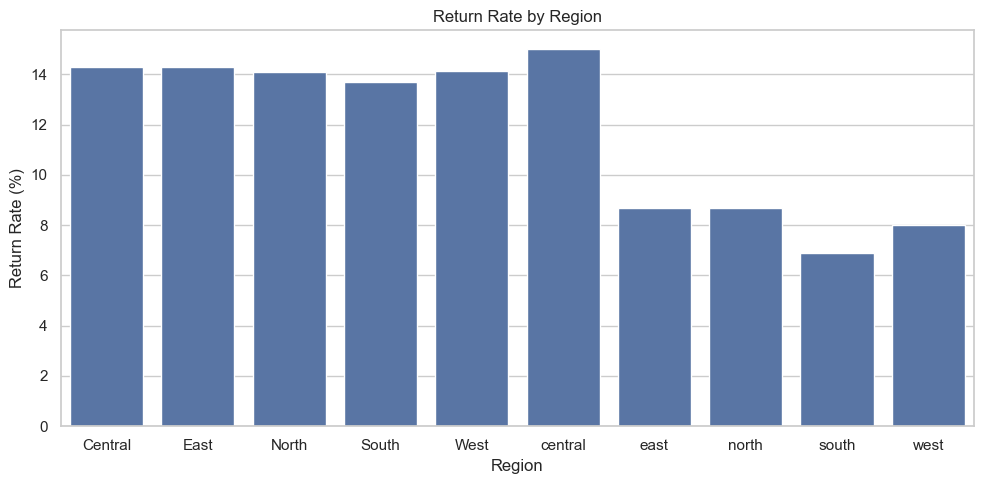

In [34]:
# Region return rate
plt.figure(figsize=(10, 5))
sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Return_Rate"
)
plt.title("Return Rate by Region")
plt.ylabel("Return Rate (%)")
plt.tight_layout()
plt.show()

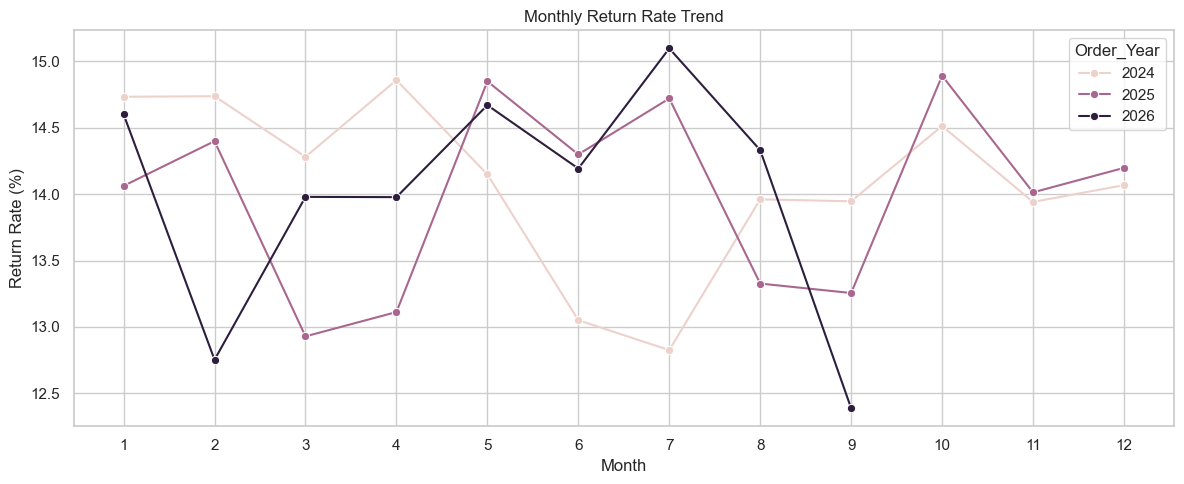

In [35]:
# Monthly return trend
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_analysis,
    x="Order_Month",
    y="Return_Rate",
    hue="Order_Year",
    marker="o"
)
plt.title("Monthly Return Rate Trend")
plt.xlabel("Month")
plt.ylabel("Return Rate (%)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

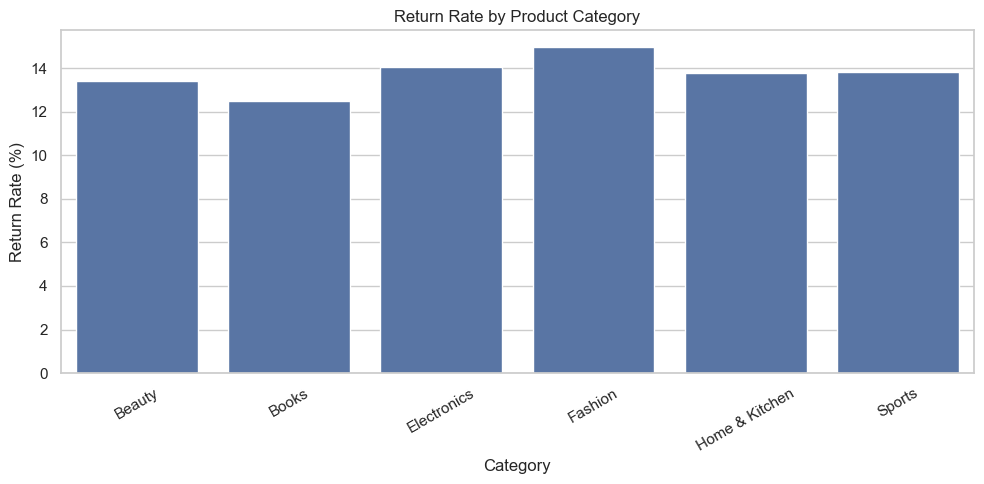

In [36]:
# Category return rate
plt.figure(figsize=(10, 5))
sns.barplot(
    data=category_analysis.reset_index(),
    x="Category",
    y="Return_Rate"
)
plt.title("Return Rate by Product Category")
plt.xticks(rotation=30)
plt.ylabel("Return Rate (%)")
plt.tight_layout()
plt.show()

In [37]:
# Check existing region labels
print("Before standardization:")
print(df["Region"].value_counts(dropna=False))

# Standardize capitalization and remove extra spaces
df["Region"] = df["Region"].str.strip().str.title()

# Recalculate region analysis
region_analysis = (
    df.groupby("Region")
      .agg(
          Total_Orders=("Order_ID", "count"),
          Returned_Orders=("Is_Returned", "sum")
      )
)

region_analysis["Return_Rate"] = (
    region_analysis["Returned_Orders"] /
    region_analysis["Total_Orders"] * 100
)

print("\nCorrected Region Analysis:")
print(region_analysis.sort_values("Return_Rate", ascending=False))

Before standardization:
Region
South      28090
West       21724
North      20061
Central    15047
East       14958
south         29
west          25
north         23
east          23
central       20
Name: count, dtype: int64

Corrected Region Analysis:
         Total_Orders  Returned_Orders  Return_Rate
Region                                             
Central         15067             2152    14.282870
East            14981             2138    14.271410
West            21749             3076    14.143179
North           20084             2832    14.100777
South           28119             3849    13.688253


In [38]:
df["Marketing_Channel"] = (
    df["Marketing_Channel"].fillna("Unknown")
)

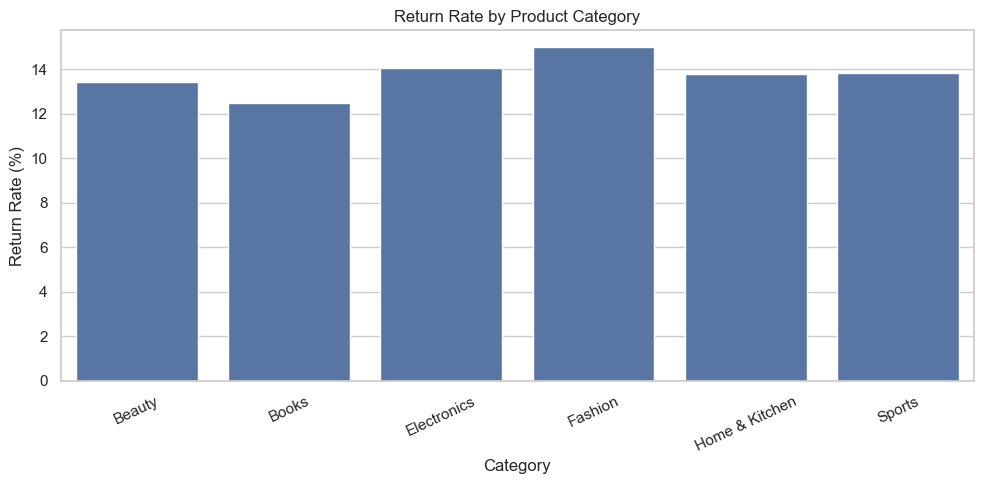

In [39]:
#  Category-wise return rate
plt.figure(figsize=(10, 5))
sns.barplot(
    data=category_analysis.reset_index(),
    x="Category",
    y="Return_Rate"
)
plt.title("Return Rate by Product Category")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

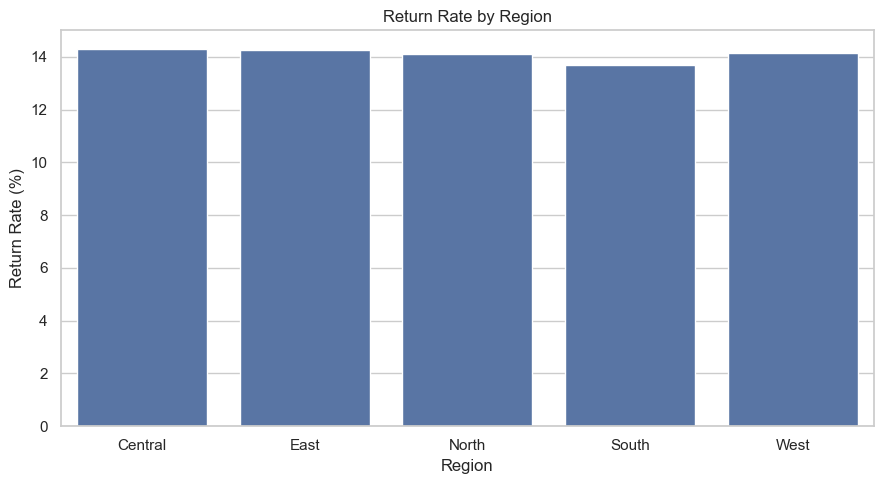

In [40]:
#Region-wise return rate
plt.figure(figsize=(9, 5))
sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Return_Rate"
)
plt.title("Return Rate by Region")
plt.ylabel("Return Rate (%)")
plt.tight_layout()
plt.show()

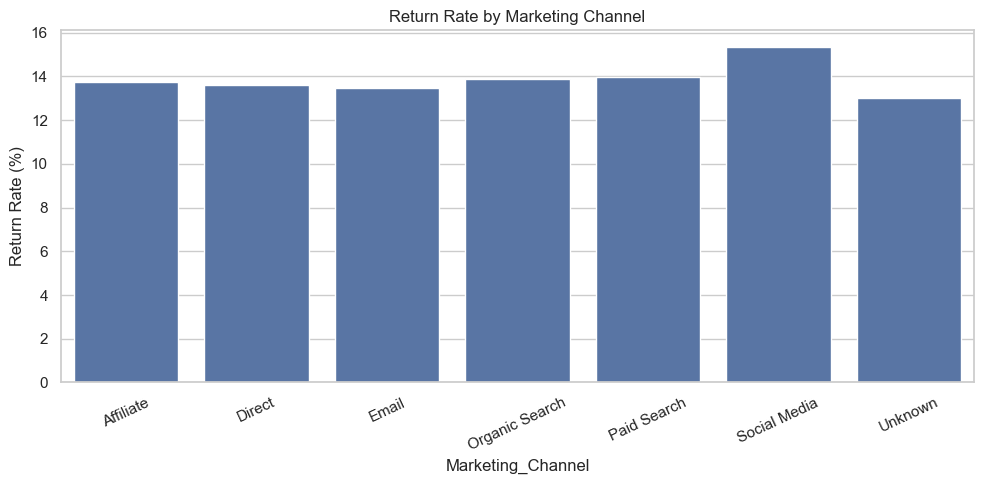

In [41]:
#  Marketing channel return rate
channel_analysis = (
    df.groupby("Marketing_Channel")
      .agg(
          Total_Orders=("Order_ID", "count"),
          Returned_Orders=("Is_Returned", "sum")
      )
)

channel_analysis["Return_Rate"] = (
    channel_analysis["Returned_Orders"] /
    channel_analysis["Total_Orders"] * 100
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=channel_analysis.reset_index(),
    x="Marketing_Channel",
      y="Return_Rate"
)
plt.title("Return Rate by Marketing Channel")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

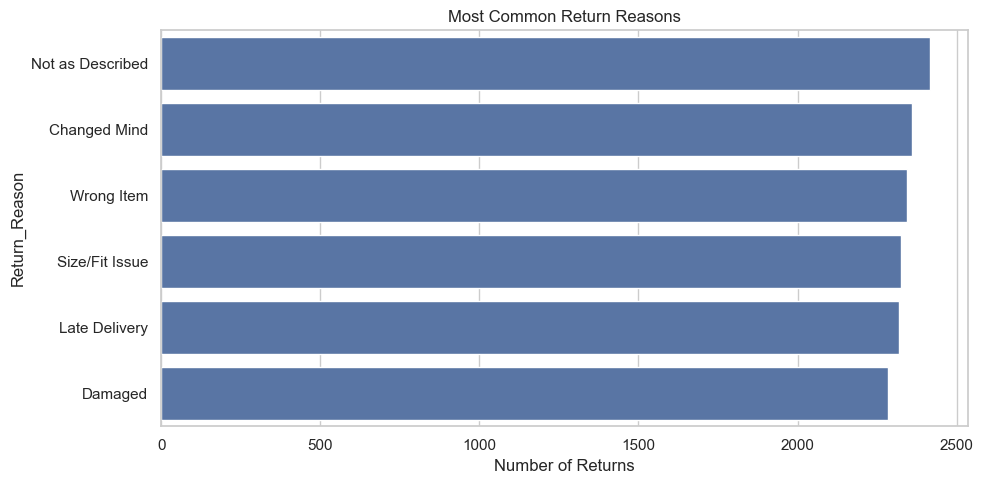

In [42]:
#  Return reasons
reason_counts = (
    df.loc[df["Return_Status"] == "Returned", "Return_Reason"]
      .value_counts()
      .reset_index()
)
reason_counts.columns = ["Return_Reason", "Count"]

plt.figure(figsize=(10, 5))
sns.barplot(
    data=reason_counts,
    x="Count",
    y="Return_Reason"
)
plt.title("Most Common Return Reasons")
plt.xlabel("Number of Returns")
plt.tight_layout()
plt.show()

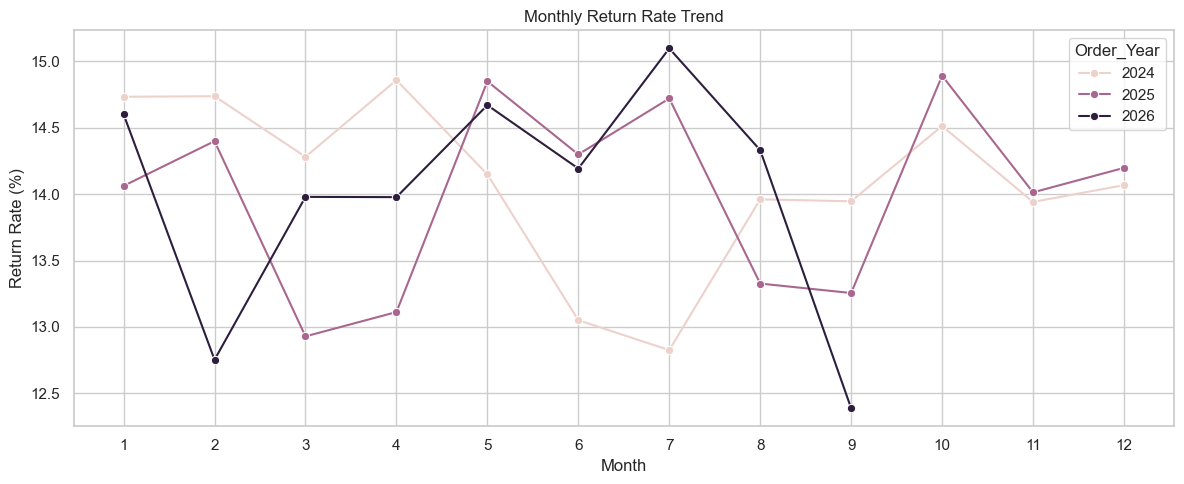

In [43]:
#  Monthly return rate trend
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_analysis,
    x="Order_Month",
    y="Return_Rate",
    hue="Order_Year",
    marker="o"
)
plt.title("Monthly Return Rate Trend")
plt.xlabel("Month")
plt.ylabel("Return Rate (%)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [44]:
df.dtypes

Order_ID                          str
Order_Date                        str
Customer_ID                       str
Product_ID                        str
Category                          str
Supplier_ID                       str
Region                            str
State                             str
Marketing_Channel                 str
Payment_Method                    str
Shipping_Method                   str
Quantity                      float64
Unit_Price                    float64
Discount_Rate                 float64
Order_Value                   float64
Delivery_Days                 float64
Customer_Rating               float64
Return_Status                     str
Return_Days_After_Delivery    float64
Return_Reason                     str
Calculated_Order_Value        float64
Value_Difference              float64
Order_Value_Mismatch            int64
Order_Year                      int64
Order_Month                     int64
Order_Quarter                   int64
Order_DayOfW

In [45]:
category_result = df.groupby("Category").agg(
    Total_Orders=("Order_ID", "count"),
    Returned_Orders=("Is_Returned", "sum"),
    Return_Rate=("Is_Returned", "mean")
)

category_result["Return_Rate"] *= 100

category_result.sort_values("Return_Rate", ascending=False)

,Total_Orders,Returned_Orders,Return_Rate
Category,,,
Fashion,27843,4175,14.994792
Electronics,21900,3082,14.073059
Sports,11861,1641,13.835258
Home & Kitchen,18254,2519,13.799715
Beauty,12084,1624,13.439259
Books,8058,1006,12.484487


In [46]:
supplier_result = df.groupby("Supplier_ID").agg(
    Total_Orders=("Order_ID", "count"),
    Returned_Orders=("Is_Returned", "sum"),
    Return_Rate=("Is_Returned", "mean")
)

supplier_result["Return_Rate"] *= 100

supplier_result.sort_values("Return_Rate", ascending=False)

,Total_Orders,Returned_Orders,Return_Rate
Supplier_ID,,,
SUP020,3318,509,15.340567
SUP008,3311,496,14.980368
SUP015,3350,499,14.895522
SUP001,3325,486,14.616541
SUP017,3333,487,14.611461
SUP022,3283,478,14.559854
SUP011,3342,484,14.482346
SUP007,3366,486,14.438503
SUP013,3320,478,14.397590


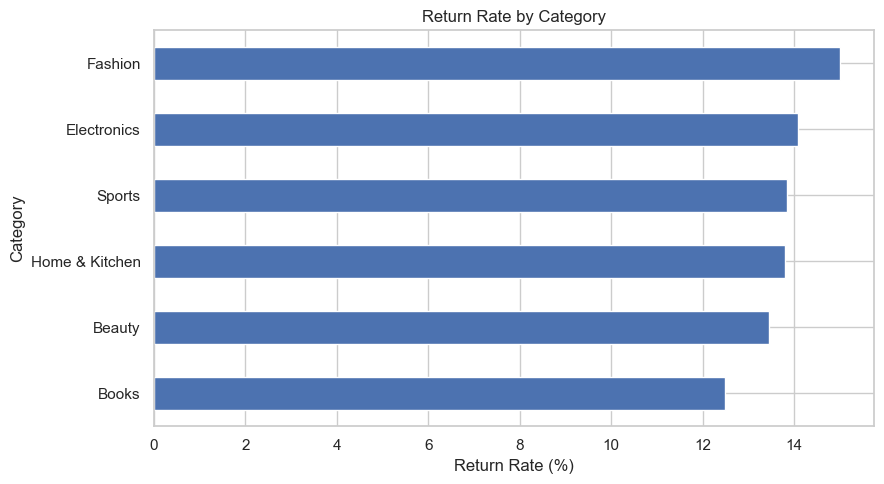

In [47]:
import matplotlib.pyplot as plt

category_result["Return_Rate"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Return Rate by Category"
)

plt.xlabel("Return Rate (%)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

1. Category-wise return analysis
Fashion recorded the highest return rate of 14.99%, followed by Electronics at 14.07%. Books had the lowest return rate at 12.48%. This indicates that the Fashion category needs further investigation to identify possible product quality, size, or customer expectation issues

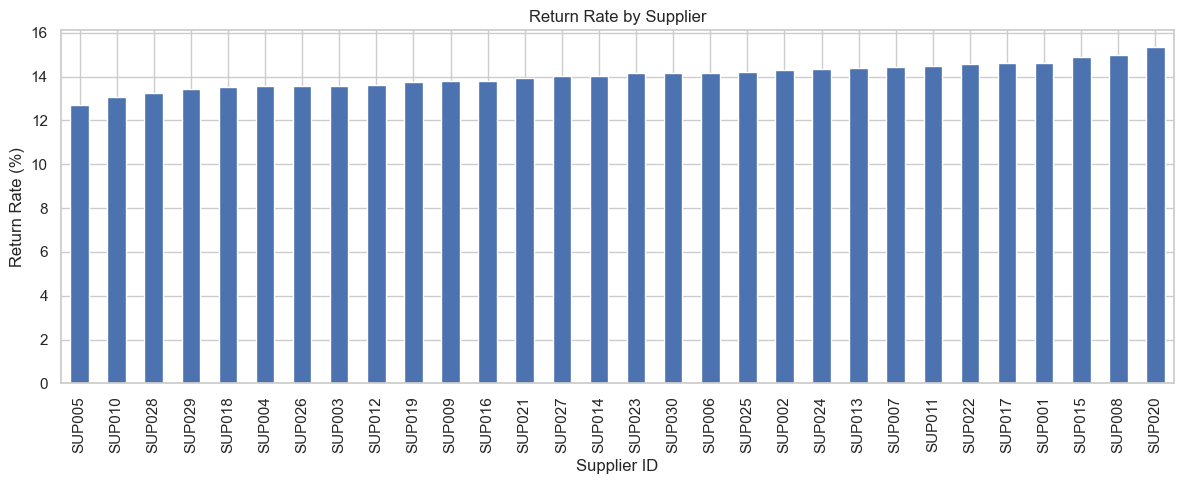

In [48]:
supplier_result["Return_Rate"].sort_values().plot(
    kind="bar",
    figsize=(12, 5),
    title="Return Rate by Supplier"
)

plt.xlabel("Supplier ID")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Supplier-wise return analysis
Supplier SUP020 recorded the highest return rate of 15.34%, with 509 returned orders out of 3,318 orders. SUP005 recorded the lowest return rate at 12.72%. The business should investigate SUP020's product quality, packaging, and fulfillment performance.

In [49]:
# Select features available at the time of placing an order
numeric_features = [
    "Quantity", "Unit_Price", "Discount_Rate",
    "Order_Year", "Order_Month", "Order_Quarter",
    "Order_DayOfWeek"
]

categorical_features = [
    "Category", "Supplier_ID", "Region", "State",
    "Marketing_Channel", "Payment_Method", "Shipping_Method"
]

feature_columns = numeric_features + categorical_features

# Create feature dataset
X = df[feature_columns].copy()

# Convert target into 0 and 1
raw_y = df["Is_Returned"]
y = pd.to_numeric(raw_y, errors="coerce")

# Handle text-based target values if present
target_mapping = {
    "true": 1, "false": 0,
    "yes": 1, "no": 0,
    "returned": 1, "not returned": 0,
    "1": 1, "0": 0
}

mapped_y = raw_y.astype(str).str.strip().str.lower().map(target_mapping)
y = y.fillna(mapped_y)

# Keep only rows with valid target values
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

# Verify target values
if not set(y.unique()).issubset({0, 1}) or y.nunique() != 2:
    raise ValueError("Target must contain both 0 and 1 only.")

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

X shape: (100000, 14)
y shape: (100000,)

Target distribution:
Is_Returned
0    85953
1    14047
Name: count, dtype: int64


In [50]:

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (80000, 14)
Testing features: (20000, 14)
Training target: (80000,)
Testing target: (20000,)


In [51]:
# Fill missing numerical values using median
# Standardize numerical features
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing created successfully.")

Numerical preprocessing created successfully.


In [52]:
# Fill missing categorical values
# Convert categorical values into numerical encoded features
from sklearn.preprocessing import OneHotEncoder
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical preprocessing created successfully.")

Categorical preprocessing created successfully.


In [53]:
# Apply numerical and categorical preprocessing separately
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Combined preprocessing created successfully.")

Combined preprocessing created successfully.


In [54]:
# Create a pipeline combining preprocessing and Logistic Regression
from sklearn.linear_model import LogisticRegression
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Logistic Regression model created successfully.")

Logistic Regression model created successfully.


In [55]:
# Train the model using training data
model.fit(X_train, y_train)

print("Model training completed.")
print("Training score:", model.score(X_train, y_train))

Model training completed.
Training score: 0.859525


In [56]:
# Predict return status for test data
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
y_pred = model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.85955
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Classification Report:
              precision    recall  f1-score   support

           0       0.86      1.00      0.92     17191
           1       0.00      0.00      0.00      2809

    accuracy                           0.86     20000
   macro avg       0.43      0.50      0.46     20000
weighted avg       0.74      0.86      0.79     20000


Confusion Matrix:
[[17191     0]
 [ 2809     0]]


In [57]:
# Calculate probability of an order being returned
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score
from sklearn.metrics import brier_score_loss
return_probability = model.predict_proba(X_test)[:, 1]

# Create prediction results
prediction_results = pd.DataFrame({
    "Actual_Return_Status": y_test,
    "Predicted_Return_Status": y_pred,
    "Return_Probability": return_probability
}, index=X_test.index)

# Display return probabilities
print("Return Probability Predictions:")
display(prediction_results.head(10))

# Calculate probability evaluation metrics
print("ROC-AUC:", roc_auc_score(y_test, return_probability))
print("PR-AUC:", average_precision_score(y_test, return_probability))
print("Brier Score:", brier_score_loss(y_test, return_probability))

Return Probability Predictions:


,Actual_Return_Status,Predicted_Return_Status,Return_Probability
70187,0,0,0.125558
91205,0,0,0.174623
36948,0,0,0.162493
7201,0,0,0.205011
10560,0,0,0.154667
6174,0,0,0.158935
40978,0,0,0.132109
47389,0,0,0.185848
47206,0,0,0.124437
57784,0,0,0.137460


ROC-AUC: 0.525300034568578
PR-AUC: 0.15418358582234515
Brier Score: 0.12062322833821476


In [58]:
# Add order IDs to the prediction results
final_predictions = df.loc[
    prediction_results.index, ["Order_ID"]
].copy()

final_predictions["Actual_Return_Status"] = (
    prediction_results["Actual_Return_Status"]
)

final_predictions["Predicted_Return_Status"] = (
    prediction_results["Predicted_Return_Status"]
)

final_predictions["Return_Probability"] = (
    prediction_results["Return_Probability"]
)

# Save prediction results as CSV
final_predictions.to_csv(
    "ecommerce_return_probability_predictions.csv",
    index=False
)

print("Prediction file saved successfully.")
print("Total predictions:", len(final_predictions))
display(final_predictions.head(10))

Prediction file saved successfully.
Total predictions: 20000


,Order_ID,Actual_Return_Status,Predicted_Return_Status,Return_Probability
70187,ORD0070188,0,0,0.125558
91205,ORD0091206,0,0,0.174623
36948,ORD0036949,0,0,0.162493
7201,ORD0007202,0,0,0.205011
10560,ORD0010561,0,0,0.154667
6174,ORD0006175,0,0,0.158935
40978,ORD0040979,0,0,0.132109
47389,ORD0047390,0,0,0.185848
47206,ORD0047207,0,0,0.124437
57784,ORD0057785,0,0,0.137460


In [59]:
# Verify whether both target columns contain the same values

return_status = pd.to_numeric(df["Return_Status"], errors="coerce")
is_returned = pd.to_numeric(df["Is_Returned"], errors="coerce")

valid = return_status.notna() & is_returned.notna()

print("Return_Status missing:", return_status.isna().sum())
print("Is_Returned missing:", is_returned.isna().sum())

print(
    "Target mismatches:",
    (return_status[valid] != is_returned[valid]).sum()
)

print("\nReturn_Status distribution:")
print(return_status.value_counts(dropna=False))

print("\nIs_Returned distribution:")
print(is_returned.value_counts(dropna=False))

Return_Status missing: 100000
Is_Returned missing: 0
Target mismatches: 0

Return_Status distribution:
Return_Status
NaN    100000
Name: count, dtype: int64

Is_Returned distribution:
Is_Returned
0    85953
1    14047
Name: count, dtype: int64


In [60]:
# Select numerical features
numeric_features = [
    "Quantity",
    "Unit_Price",
    "Discount_Rate",
    "Order_Year",
    "Order_Month",
    "Order_Quarter",
    "Order_DayOfWeek"
]

# Select categorical features
categorical_features = [
    "Category",
    "Supplier_ID",
    "Region",
    "State",
    "Marketing_Channel",
    "Payment_Method",
    "Shipping_Method"
]

# Combine selected features
feature_columns = numeric_features + categorical_features

# Create input and target variables
X = df[feature_columns].copy()
y = pd.to_numeric(df["Is_Returned"], errors="coerce")

# Remove rows with missing target
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

# Verify the dataset
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (100000, 14)
Target shape: (100000,)

Target distribution:
Is_Returned
0    85953
1    14047
Name: count, dtype: int64


In [61]:
# First separate 20% data for final testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Divide remaining data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

# Verify the split
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (60000, 14)
Validation: (20000, 14)
Testing: (20000, 14)


In [62]:
# Handle missing numerical and categorical values
# Encode categorical features and scale numerical features
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Use balanced class weights to handle imbalanced target classes
# C=0.001 was the best regularization setting in the earlier experiment
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=0.001,
        class_weight="balanced",
        max_iter=3000,
        solver="lbfgs",
        random_state=42
    ))
])

print("Improved Logistic Regression pipeline created.")

Improved Logistic Regression pipeline created.


In [63]:
# Train model using training data only
model.fit(X_train, y_train)

# Predict return probabilities on validation data
val_probabilities = model.predict_proba(X_val)[:, 1]

# Find the threshold that gives the highest validation F1 score
best_threshold = 0.50
best_f1 = -1

for threshold in np.arange(0.05, 0.51, 0.01):

    # Convert probabilities into predicted classes
    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    # Calculate validation F1 score
    current_f1 = f1_score(
        y_val,
        val_predictions,
        zero_division=0
    )

    # Store the best threshold
    if current_f1 > best_f1:
        best_f1 = current_f1
        best_threshold = threshold

print("Best Threshold:", best_threshold)
print("Validation F1 Score:", best_f1)

Best Threshold: 0.44000000000000006
Validation F1 Score: 0.2463876323070842


In [64]:
# Predict probabilities on untouched test data
test_probabilities = model.predict_proba(X_test)[:, 1]

# Apply the selected validation threshold
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Calculate final test metrics
print("Final Test Accuracy:", accuracy_score(y_test, test_predictions))
print("Final Test Precision:", precision_score(y_test, test_predictions, zero_division=0))
print("Final Test Recall:", recall_score(y_test, test_predictions, zero_division=0))
print("Final Test F1 Score:", f1_score(y_test, test_predictions, zero_division=0))

print("\nROC-AUC:", roc_auc_score(y_test, test_probabilities))
print("PR-AUC:", average_precision_score(y_test, test_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

# Prepare final test prediction results
final_results = pd.DataFrame({
    "Order_ID": df.loc[X_test.index, "Order_ID"],
    "Actual_Return_Status": y_test,
    "Predicted_Return_Status": test_predictions,
    "Return_Probability": test_probabilities
}, index=X_test.index)

# Export final results
final_results.to_csv(
    "improved_logistic_regression_predictions.csv",
    index=False
)

print("\nFinal prediction file saved.")
print("Total test predictions:", len(final_results))
display(final_results.head(10))

Final Test Accuracy: 0.1413
Final Test Precision: 0.14038952585991088
Final Test Recall: 0.9982200071199715
Final Test F1 Score: 0.24615924852954085

ROC-AUC: 0.5300827080095787
PR-AUC: 0.15729783352313956

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.00      0.00     17191
           1       0.14      1.00      0.25      2809

    accuracy                           0.14     20000
   macro avg       0.48      0.50      0.12     20000
weighted avg       0.72      0.14      0.04     20000


Confusion Matrix:
[[   22 17169]
 [    5  2804]]

Final prediction file saved.
Total test predictions: 20000


,Order_ID,Actual_Return_Status,Predicted_Return_Status,Return_Probability
70187,ORD0070188,0,1,0.478079
91205,ORD0091206,0,1,0.535735
36948,ORD0036949,0,1,0.533978
7201,ORD0007202,0,1,0.574933
10560,ORD0010561,0,1,0.511208
6174,ORD0006175,0,1,0.518794
40978,ORD0040979,0,1,0.486975
47389,ORD0047390,0,1,0.555434
47206,ORD0047207,0,1,0.472283
57784,ORD0057785,0,1,0.512161


In [65]:
# Verify required columns
required_columns = [
    "Order_ID", "Product_ID", "Category", "Supplier_ID",
    "Region", "State", "Marketing_Channel",
    "Quantity", "Unit_Price", "Discount_Rate",
    "Order_Year", "Order_Month", "Order_Quarter",
    "Order_DayOfWeek", "Is_Returned", "Return_Reason"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Use Is_Returned as the target
df["Is_Returned"] = pd.to_numeric(
    df["Is_Returned"], errors="coerce"
)

df = df.dropna(subset=["Is_Returned"]).copy()

if not set(df["Is_Returned"].unique()).issubset({0, 1}):
    raise ValueError("Target must contain only 0 and 1.")

df["Is_Returned"] = df["Is_Returned"].astype(int)

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["Is_Returned"].value_counts())

print("\nMissing Return Reason:")
print(df["Return_Reason"].isna().sum())

Dataset shape: (100000, 28)

Target distribution:
Is_Returned
0    85953
1    14047
Name: count, dtype: int64

Missing Return Reason:
85953


In [66]:
# Calculate overall return statistics
total_orders = len(df)
returned_orders = df["Is_Returned"].sum()
overall_return_rate = returned_orders / total_orders * 100

print("Total Orders:", total_orders)
print("Returned Orders:", returned_orders)
print("Overall Return Rate:", round(overall_return_rate, 2), "%")

# Calculate category-wise return rate
category_analysis = (
    df.groupby("Category", dropna=False)
    .agg(
        Total_Orders=("Is_Returned", "size"),
        Returned_Orders=("Is_Returned", "sum")
    )
    .reset_index()
)

category_analysis["Return_Rate"] = (
    category_analysis["Returned_Orders"]
    / category_analysis["Total_Orders"] * 100
)

category_analysis = category_analysis.sort_values(
    "Return_Rate", ascending=False
)

display(category_analysis)

Total Orders: 100000
Returned Orders: 14047
Overall Return Rate: 14.05 %


,Category,Total_Orders,Returned_Orders,Return_Rate
3,Fashion,27843,4175,14.994792
2,Electronics,21900,3082,14.073059
5,Sports,11861,1641,13.835258
4,Home & Kitchen,18254,2519,13.799715
0,Beauty,12084,1624,13.439259
1,Books,8058,1006,12.484487


In [67]:
# Calculate supplier-wise return statistics
supplier_analysis = (
    df.groupby("Supplier_ID", dropna=False)
    .agg(
        Total_Orders=("Is_Returned", "size"),
        Returned_Orders=("Is_Returned", "sum")
    )
    .reset_index()
)

supplier_analysis["Return_Rate"] = (
    supplier_analysis["Returned_Orders"]
    / supplier_analysis["Total_Orders"] * 100
)

supplier_analysis = supplier_analysis.sort_values(
    "Return_Rate", ascending=False
)

display(supplier_analysis)

,Supplier_ID,Total_Orders,Returned_Orders,Return_Rate
19,SUP020,3318,509,15.340567
7,SUP008,3311,496,14.980368
14,SUP015,3350,499,14.895522
0,SUP001,3325,486,14.616541
16,SUP017,3333,487,14.611461
21,SUP022,3283,478,14.559854
10,SUP011,3342,484,14.482346
6,SUP007,3366,486,14.438503
12,SUP013,3320,478,14.397590
23,SUP024,3488,501,14.363532


In [68]:
# Analyze return rates by region
region_analysis = (
    df.groupby("Region", dropna=False)
    .agg(
        Total_Orders=("Is_Returned", "size"),
        Returned_Orders=("Is_Returned", "sum")
    )
    .reset_index()
)

region_analysis["Return_Rate"] = (
    region_analysis["Returned_Orders"]
    / region_analysis["Total_Orders"] * 100
)

# Analyze return rates by state
state_analysis = (
    df.groupby("State", dropna=False)
    .agg(
        Total_Orders=("Is_Returned", "size"),
        Returned_Orders=("Is_Returned", "sum")
    )
    .reset_index()
)

state_analysis["Return_Rate"] = (
    state_analysis["Returned_Orders"]
    / state_analysis["Total_Orders"] * 100
)

# Analyze return rates by marketing channel
channel_analysis = (
    df.groupby("Marketing_Channel", dropna=False)
    .agg(
        Total_Orders=("Is_Returned", "size"),
        Returned_Orders=("Is_Returned", "sum")
    )
    .reset_index()
)

channel_analysis["Return_Rate"] = (
    channel_analysis["Returned_Orders"]
    / channel_analysis["Total_Orders"] * 100
)

display(region_analysis.sort_values("Return_Rate", ascending=False))
display(state_analysis.sort_values("Return_Rate", ascending=False))
display(channel_analysis.sort_values("Return_Rate", ascending=False))

,Region,Total_Orders,Returned_Orders,Return_Rate
0,Central,15067,2152,14.282870
1,East,14981,2138,14.271410
4,West,21749,3076,14.143179
2,North,20084,2832,14.100777
3,South,28119,3849,13.688253


,State,Total_Orders,Returned_Orders,Return_Rate
12,Odisha,3664,545,14.874454
13,Punjab,5019,740,14.743973
5,Gujarat,5398,783,14.505372
10,Madhya Pradesh,7456,1079,14.471567
16,Telangana,5619,804,14.308596
1,Bihar,3769,538,14.274343
7,Jharkhand,3729,531,14.239743
4,Goa,5453,775,14.212360
2,Chhattisgarh,7611,1073,14.098016
17,Uttar Pradesh,5148,721,14.005439


,Marketing_Channel,Total_Orders,Returned_Orders,Return_Rate
5,Social Media,18007,2762,15.338479
4,Paid Search,19937,2783,13.958971
3,Organic Search,25123,3485,13.871751
0,Affiliate,10046,1379,13.726856
1,Direct,14789,2010,13.591183
2,Email,11898,1602,13.464448
6,Unknown,200,26,13.000000


In [69]:
# Analyze reasons only for orders that were returned
returned_data = df[df["Is_Returned"] == 1].copy()

# Count recorded and missing return reasons
reason_analysis = (
    returned_data["Return_Reason"]
    .fillna("Not Recorded")
    .value_counts()
    .reset_index()
)

reason_analysis.columns = ["Return_Reason", "Return_Count"]

reason_analysis["Percentage"] = (
    reason_analysis["Return_Count"]
    / len(returned_data) * 100
)

display(reason_analysis)

,Return_Reason,Return_Count,Percentage
0,Not as Described,2416,17.199402
1,Changed Mind,2359,16.793621
2,Wrong Item,2344,16.686837
3,Size/Fit Issue,2324,16.544458
4,Late Delivery,2320,16.515982
5,Damaged,2284,16.259700


In [70]:
# Select order-time numerical features
numeric_features = [
    "Quantity",
    "Unit_Price",
    "Discount_Rate",
    "Order_Year",
    "Order_Month",
    "Order_Quarter",
    "Order_DayOfWeek"
]

# Select order-time categorical features
categorical_features = [
    "Category",
    "Supplier_ID",
    "Region",
    "State",
    "Marketing_Channel",
    "Payment_Method",
    "Shipping_Method"
]

# Create feature and target datasets
feature_columns = numeric_features + categorical_features

X = df[feature_columns].copy()
y = df["Is_Returned"].copy()

# Split into training, validation and testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25, random_state=42,
    stratify=y_train_val
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (60000, 14)
Validation: (20000, 14)
Testing: (20000, 14)


In [71]:
# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant", fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Build Logistic Regression pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=0.001,
        class_weight="balanced",
        max_iter=3000,
        solver="lbfgs",
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [72]:
# Generate validation probabilities
validation_probabilities = model.predict_proba(X_val)[:, 1]

# Find the threshold with the highest validation F1
best_threshold = 0.50
best_f1 = -1

for threshold in np.arange(0.05, 0.96, 0.01):

    validation_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    current_f1 = f1_score(
        y_val, validation_predictions,
        zero_division=0
    )

    if current_f1 > best_f1:
        best_f1 = current_f1
        best_threshold = threshold

print("Best Threshold:", best_threshold)
print("Validation F1:", best_f1)

Best Threshold: 0.44000000000000006
Validation F1: 0.2463876323070842


In [73]:
# Generate predictions on untouched test data
test_probabilities = model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Calculate final performance metrics
accuracy = accuracy_score(y_test, test_predictions)
precision = precision_score(y_test, test_predictions, zero_division=0)
recall = recall_score(y_test, test_predictions, zero_division=0)
f1 = f1_score(y_test, test_predictions, zero_division=0)
roc_auc = roc_auc_score(y_test, test_probabilities)
pr_auc = average_precision_score(y_test, test_probabilities)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

print("\nClassification Report:")
print(classification_report(
    y_test, test_predictions, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

Accuracy: 0.1413
Precision: 0.14038952585991088
Recall: 0.9982200071199715
F1 Score: 0.24615924852954085
ROC-AUC: 0.5300827080095787
PR-AUC: 0.15729783352313956

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.00      0.00     17191
           1       0.14      1.00      0.25      2809

    accuracy                           0.14     20000
   macro avg       0.48      0.50      0.12     20000
weighted avg       0.72      0.14      0.04     20000


Confusion Matrix:
[[   22 17169]
 [    5  2804]]


In [74]:
# Create order-level test predictions
final_predictions = pd.DataFrame({
    "Order_ID": df.loc[X_test.index, "Order_ID"],
    "Product_ID": df.loc[X_test.index, "Product_ID"],
    "Actual_Return_Status": y_test,
    "Predicted_Return_Status": test_predictions,
    "Return_Probability": test_probabilities
}, index=X_test.index)

# Add the selected threshold for reference
final_predictions["Risk_Threshold"] = best_threshold

# Aggregate probability by product
product_risk = (
    final_predictions.groupby("Product_ID")
    .agg(
        Orders_Scored=("Order_ID", "count"),
        Average_Return_Probability=("Return_Probability", "mean"),
        Actual_Return_Rate=("Actual_Return_Status", "mean")
    )
    .reset_index()
)

product_risk["Actual_Return_Rate"] *= 100
product_risk["Average_Return_Probability"] *= 100

# Flag candidate high-risk products using the selected threshold
product_risk["Risk_Status"] = np.where(
    product_risk["Average_Return_Probability"] >= best_threshold * 100,
    "High",
    "Below High-Risk Threshold"
)

# Export test predictions
final_predictions.to_csv(
    "ecommerce_return_predictions.csv", index=False
)

# Export candidate high-risk products
high_risk_products = product_risk[
    product_risk["Risk_Status"] == "High"
].sort_values(
    "Average_Return_Probability", ascending=False
)

high_risk_products.to_csv(
    "ecommerce_high_risk_products.csv", index=False
)

print("Prediction records:", len(final_predictions))
print("Candidate high-risk products:", len(high_risk_products))

display(high_risk_products.head(10))

Prediction records: 20000
Candidate high-risk products: 2500


,Product_ID,Orders_Scored,Average_Return_Probability,Actual_Return_Rate,Risk_Status
644,PRD00645,4,53.400994,0.0,High
1629,PRD01630,2,53.223746,0.0,High
1844,PRD01845,3,53.188167,0.0,High
1664,PRD01665,6,53.187400,0.0,High
2151,PRD02152,4,53.017326,0.0,High
1638,PRD01639,5,52.987804,40.0,High
794,PRD00795,5,52.979891,20.0,High
1897,PRD01898,12,52.922013,25.0,High
1394,PRD01395,5,52.737394,0.0,High
1118,PRD01119,4,52.734959,0.0,High


In [75]:
print("TEST PROBABILITY CHECK")
print("----------------------")

print("Minimum Probability:", test_probabilities.min())
print("Maximum Probability:", test_probabilities.max())

print("Selected Threshold:", best_threshold)

print("\nFINAL PREDICTIONS COLUMNS")
print(final_predictions.columns.tolist())

print("\nFINAL PREDICTIONS SAMPLE")
display(final_predictions.head(10))

print("\nHIGH RISK PRODUCTS COLUMNS")
print(high_risk_products.columns.tolist())

print("\nHIGH RISK PRODUCTS SAMPLE")
display(high_risk_products.head(10))

TEST PROBABILITY CHECK
----------------------
Minimum Probability: 0.4285557331538002
Maximum Probability: 0.6084943517371078
Selected Threshold: 0.44000000000000006

FINAL PREDICTIONS COLUMNS
['Order_ID', 'Product_ID', 'Actual_Return_Status', 'Predicted_Return_Status', 'Return_Probability', 'Risk_Threshold']

FINAL PREDICTIONS SAMPLE


,Order_ID,Product_ID,Actual_Return_Status,Predicted_Return_Status,Return_Probability,Risk_Threshold
70187,ORD0070188,PRD00043,0,1,0.478079,0.44
91205,ORD0091206,PRD01309,0,1,0.535735,0.44
36948,ORD0036949,PRD01664,0,1,0.533978,0.44
7201,ORD0007202,PRD00864,0,1,0.574933,0.44
10560,ORD0010561,PRD02301,0,1,0.511208,0.44
6174,ORD0006175,PRD01434,0,1,0.518794,0.44
40978,ORD0040979,PRD01298,0,1,0.486975,0.44
47389,ORD0047390,PRD00338,0,1,0.555434,0.44
47206,ORD0047207,PRD02254,0,1,0.472283,0.44
57784,ORD0057785,PRD01677,0,1,0.512161,0.44



HIGH RISK PRODUCTS COLUMNS
['Product_ID', 'Orders_Scored', 'Average_Return_Probability', 'Actual_Return_Rate', 'Risk_Status']

HIGH RISK PRODUCTS SAMPLE


,Product_ID,Orders_Scored,Average_Return_Probability,Actual_Return_Rate,Risk_Status
644,PRD00645,4,53.400994,0.0,High
1629,PRD01630,2,53.223746,0.0,High
1844,PRD01845,3,53.188167,0.0,High
1664,PRD01665,6,53.187400,0.0,High
2151,PRD02152,4,53.017326,0.0,High
1638,PRD01639,5,52.987804,40.0,High
794,PRD00795,5,52.979891,20.0,High
1897,PRD01898,12,52.922013,25.0,High
1394,PRD01395,5,52.737394,0.0,High
1118,PRD01119,4,52.734959,0.0,High


In [76]:
# Check probability scale in final_predictions
print("Original probability sample:")
display(final_predictions[
    ["Product_ID", "Return_Probability"]
].head())

# Verify product risk probability scale
print("\nCurrent high-risk product probability:")
display(high_risk_products[
    ["Product_ID", "Average_Return_Probability"]
].head())

Original probability sample:


,Product_ID,Return_Probability
70187,PRD00043,0.478079
91205,PRD01309,0.535735
36948,PRD01664,0.533978
7201,PRD00864,0.574933
10560,PRD02301,0.511208



Current high-risk product probability:


,Product_ID,Average_Return_Probability
644,PRD00645,53.400994
1629,PRD01630,53.223746
1844,PRD01845,53.188167
1664,PRD01665,53.187400
2151,PRD02152,53.017326


In [77]:
import numpy as np
import pandas as pd

# Remove target leakage and identifier columns
leakage_columns = [
    "Is_Returned",
    "Return_Status",
    "Return_Reason",
    "Return_Days_After_Delivery",
    "Actual_Return_Status"
]

identifier_columns = [
    "Order_ID",
    "Customer_ID",
    "Product_ID"
]

columns_to_remove = leakage_columns + identifier_columns

X_model = X.drop(
    columns=columns_to_remove,
    errors="ignore"
).copy()

# Align existing train, validation and test data
X_train_model = X_model.loc[X_train.index].copy()
X_val_model = X_model.loc[X_val.index].copy()
X_test_model = X_model.loc[X_test.index].copy()

y_train_final = y_train.reindex(X_train_model.index)
y_val_final = y_val.reindex(X_val_model.index)
y_test_final = y_test.reindex(X_test_model.index)

# Validation checks
assert X_train_model.index.equals(y_train_final.index)
assert X_val_model.index.equals(y_val_final.index)
assert X_test_model.index.equals(y_test_final.index)

assert not y_train_final.isna().any()
assert not y_val_final.isna().any()
assert not y_test_final.isna().any()

assert X_model.shape[1] > 0

print(" FEATURE VALIDATION")
print("--------------------------")
print("Removed columns:", [c for c in columns_to_remove if c in X.columns])
print("Remaining features:", X_model.columns.tolist())
print("Training shape:", X_train_model.shape)
print("Validation shape:", X_val_model.shape)
print("Testing shape:", X_test_model.shape)
print("\nTraining target distribution:")
print(y_train_final.value_counts())
print("\nFeature validation completed.")

 FEATURE VALIDATION
--------------------------
Removed columns: []
Remaining features: ['Quantity', 'Unit_Price', 'Discount_Rate', 'Order_Year', 'Order_Month', 'Order_Quarter', 'Order_DayOfWeek', 'Category', 'Supplier_ID', 'Region', 'State', 'Marketing_Channel', 'Payment_Method', 'Shipping_Method']
Training shape: (60000, 14)
Validation shape: (20000, 14)
Testing shape: (20000, 14)

Training target distribution:
Is_Returned
0    51571
1     8429
Name: count, dtype: int64

Feature validation completed.


In [78]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

numeric_features_final = (
    X_train_model.select_dtypes(include=np.number).columns.tolist()
)

categorical_features_final = (
    X_train_model.select_dtypes(exclude=np.number).columns.tolist()
)

transformers_final = []

if numeric_features_final:
    numeric_pipeline_final = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    transformers_final.append(
        ("numeric", numeric_pipeline_final, numeric_features_final)
    )

if categorical_features_final:
    categorical_pipeline_final = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers_final.append(
        ("categorical", categorical_pipeline_final, categorical_features_final)
    )

preprocessor_final = ColumnTransformer(
    transformers=transformers_final
)

final_model = Pipeline([
    ("preprocessor", preprocessor_final),
    ("classifier", LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        random_state=42
    ))
])

final_model.fit(X_train_model, y_train_final)

print("STEP 2: MODEL TRAINING")
print("----------------------")
print("Numeric features:", len(numeric_features_final))
print("Categorical features:", len(categorical_features_final))
print("Logistic Regression training completed.")

STEP 2: MODEL TRAINING
----------------------
Numeric features: 7
Categorical features: 7
Logistic Regression training completed.


In [79]:
from sklearn.metrics import (
    precision_recall_curve,
    f1_score,
    precision_score,
    recall_score
)

val_probabilities_final = final_model.predict_proba(
    X_val_model
)[:, 1]

precision_values, recall_values, threshold_values = (
    precision_recall_curve(
        y_val_final,
        val_probabilities_final
    )
)

if len(threshold_values) > 0:
    f1_values = (
        2 * precision_values[:-1] * recall_values[:-1]
        / (
            precision_values[:-1]
            + recall_values[:-1]
            + 1e-12
        )
    )

    best_index = np.argmax(f1_values)
    final_threshold = float(threshold_values[best_index])

else:
    final_threshold = 0.5

val_predictions_final = (
    val_probabilities_final >= final_threshold
).astype(int)

print("STEP 3: VALIDATION RESULTS")
print("-------------------------")
print("Selected threshold:", final_threshold)

print(
    "Validation Precision:",
    round(
        precision_score(
            y_val_final,
            val_predictions_final,
            zero_division=0
        ), 4
    )
)

print(
    "Validation Recall:",
    round(
        recall_score(
            y_val_final,
            val_predictions_final,
            zero_division=0
        ), 4
    )
)

print(
    "Validation F1:",
    round(
        f1_score(
            y_val_final,
            val_predictions_final,
            zero_division=0
        ), 4
    )
)

STEP 3: VALIDATION RESULTS
-------------------------
Selected threshold: 0.09243348829249849
Validation Precision: 0.1405
Validation Recall: 1.0
Validation F1: 0.2464


In [80]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from sklearn.dummy import DummyClassifier

test_probabilities_final = final_model.predict_proba(
    X_test_model
)[:, 1]

test_predictions_final = (
    test_probabilities_final >= final_threshold
).astype(int)

# Logistic Regression evaluation
final_accuracy = accuracy_score(
    y_test_final, test_predictions_final
)

final_precision = precision_score(
    y_test_final, test_predictions_final,
    zero_division=0
)

final_recall = recall_score(
    y_test_final, test_predictions_final,
    zero_division=0
)

final_f1 = f1_score(
    y_test_final, test_predictions_final,
    zero_division=0
)

final_roc_auc = roc_auc_score(
    y_test_final, test_probabilities_final
)

final_pr_auc = average_precision_score(
    y_test_final, test_probabilities_final
)

# Majority-class baseline
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train_model, y_train_final)

baseline_predictions = baseline_model.predict(X_test_model)

baseline_accuracy = accuracy_score(
    y_test_final, baseline_predictions
)

print("STEP 4: FINAL TEST RESULTS")
print("--------------------------")

print("Accuracy:", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall:", round(final_recall, 4))
print("F1 Score:", round(final_f1, 4))
print("ROC-AUC:", round(final_roc_auc, 4))
print("PR-AUC:", round(final_pr_auc, 4))

print("\nBaseline Accuracy:", round(baseline_accuracy, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_final, test_predictions_final))

print("\nClassification Report:")
print(
    classification_report(
        y_test_final,
        test_predictions_final,
        zero_division=0
    )
)

STEP 4: FINAL TEST RESULTS
--------------------------
Accuracy: 0.1406
Precision: 0.1404
Recall: 0.9996
F1 Score: 0.2463
ROC-AUC: 0.5268
PR-AUC: 0.1551

Baseline Accuracy: 0.8596

Confusion Matrix:
[[    4 17187]
 [    1  2808]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.00      0.00     17191
           1       0.14      1.00      0.25      2809

    accuracy                           0.14     20000
   macro avg       0.47      0.50      0.12     20000
weighted avg       0.71      0.14      0.03     20000



In [81]:
# Build order-level prediction results
order_details = df.loc[
    X_test_model.index,
    ["Order_ID", "Product_ID"]
].copy()

final_predictions = pd.DataFrame({
    "Order_ID": order_details["Order_ID"],
    "Product_ID": order_details["Product_ID"],
    "Actual_Return_Status": y_test_final,
    "Predicted_Return_Status": test_predictions_final,
    "Return_Probability": test_probabilities_final,
    "Risk_Threshold": final_threshold
})

# Product-level summary
product_risk = (
    final_predictions
    .groupby("Product_ID")
    .agg(
        Orders_Scored=("Order_ID", "count"),
        Average_Return_Probability=("Return_Probability", "mean"),
        Actual_Return_Rate=("Actual_Return_Status", "mean")
    )
    .reset_index()
)

# Convert probabilities and actual return rate into percentages
product_risk["Average_Return_Probability"] *= 100
product_risk["Actual_Return_Rate"] *= 100

# Identify top 25% relative risk candidates
product_risk = product_risk.sort_values(
    "Average_Return_Probability",
    ascending=False
).reset_index(drop=True)

number_of_high_risk = max(
    1,
    int(np.ceil(len(product_risk) * 0.25))
)

product_risk["Risk_Status"] = "Standard"

product_risk.loc[
    :number_of_high_risk - 1,
    "Risk_Status"
] = "High"

high_risk_products = product_risk[
    product_risk["Risk_Status"] == "High"
].copy()

# Export deliverables
final_predictions.to_csv(
    "ecommerce_return_predictions.csv",
    index=False
)

high_risk_products.to_csv(
    "ecommerce_high_risk_products.csv",
    index=False
)

product_risk.to_csv(
    "ecommerce_product_risk_summary.csv",
    index=False
)

import joblib

joblib.dump(
    final_model,
    "ecommerce_logistic_regression_model.joblib"
)

print("STEP 5: FINAL DELIVERABLES")
print("--------------------------")
print("Test orders scored:", len(final_predictions))
print("Products analyzed:", len(product_risk))
print("High-risk candidate products:", len(high_risk_products))

print("\nHigh-risk product sample:")
display(high_risk_products.head(10))

print("\nExported files:")
print("1. ecommerce_return_predictions.csv")
print("2. ecommerce_high_risk_products.csv")
print("3. ecommerce_product_risk_summary.csv")
print("4. ecommerce_logistic_regression_model.joblib")

print("\nPython implementation completed.")

STEP 5: FINAL DELIVERABLES
--------------------------
Test orders scored: 20000
Products analyzed: 2500
High-risk candidate products: 625

High-risk product sample:


,Product_ID,Orders_Scored,Average_Return_Probability,Actual_Return_Rate,Risk_Status
0,PRD00645,4,17.770015,0.000000,High
1,PRD01845,3,17.613229,0.000000,High
2,PRD01665,6,17.333408,0.000000,High
3,PRD00795,5,17.290712,20.000000,High
4,PRD00885,8,17.286093,37.500000,High
5,PRD02385,10,17.242993,10.000000,High
6,PRD01898,12,17.162967,25.000000,High
7,PRD01395,5,17.039965,0.000000,High
8,PRD00015,7,17.027856,14.285714,High
9,PRD02025,6,17.011118,33.333333,High



Exported files:
1. ecommerce_return_predictions.csv
2. ecommerce_high_risk_products.csv
3. ecommerce_product_risk_summary.csv
4. ecommerce_logistic_regression_model.joblib

Python implementation completed.


In [82]:
# Only order-time features; avoid return-related data leakage

feature_cols = [
    "Quantity",
    "Unit_Price",
    "Discount_Rate",
    "Order_Value",
    "Order_Year",
    "Order_Month",
    "Order_Quarter",
    "Order_DayOfWeek",
    "Category",
    "Supplier_ID",
    "Region",
    "State",
    "Marketing_Channel",
    "Payment_Method",
    "Shipping_Method"
]

X_new = df[feature_cols].copy()
y_new = df["Is_Returned"].astype(int).copy()

# Preserve the existing train/validation/test split
X_train_new = X_new.loc[X_train.index]
X_val_new = X_new.loc[X_val.index]
X_test_new = X_new.loc[X_test.index]

y_train_new = y_new.loc[y_train.index]
y_val_new = y_new.loc[y_val.index]
y_test_new = y_new.loc[y_test.index]

print("Training:", X_train_new.shape)
print("Validation:", X_val_new.shape)
print("Testing:", X_test_new.shape)
print("Features:", len(feature_cols))

Training: (60000, 15)
Validation: (20000, 15)
Testing: (20000, 15)
Features: 15


In [83]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, precision_score, recall_score
from sklearn.utils.class_weight import compute_sample_weight

numeric_features = X_train_new.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train_new.select_dtypes(exclude=["number"]).columns.tolist()

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        C=0.1
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150,
        max_leaf_nodes=15,
        learning_rate=0.05,
        l2_regularization=2,
        random_state=42
    )
}

trained_models = {}
validation_results = []

X_train_processed = preprocessor.fit_transform(X_train_new)
X_val_processed = preprocessor.transform(X_val_new)

for name, estimator in models.items():

    if name == "Hist Gradient Boosting":
        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train_new
        )
        estimator.fit(X_train_processed, y_train_new,
                      sample_weight=sample_weights)
    else:
        estimator.fit(X_train_processed, y_train_new)

    probabilities = estimator.predict_proba(X_val_processed)[:, 1]

    pr_auc = average_precision_score(y_val_new, probabilities)
    roc_auc = roc_auc_score(y_val_new, probabilities)

    trained_models[name] = estimator

    validation_results.append({
        "Model": name,
        "PR_AUC": pr_auc,
        "ROC_AUC": roc_auc
    })

validation_results = pd.DataFrame(validation_results)
validation_results = validation_results.sort_values(
    "PR_AUC", ascending=False
)

display(validation_results)

,Model,PR_AUC,ROC_AUC
3,Hist Gradient Boosting,0.153346,0.528872
1,Random Forest,0.151997,0.525468
2,Extra Trees,0.150370,0.522611
0,Logistic Regression,0.148303,0.520090


In [84]:
best_model_name = validation_results.iloc[0]["Model"]
best_model = trained_models[best_model_name]

val_probabilities = best_model.predict_proba(X_val_processed)[:, 1]

threshold_results = []

for threshold in np.arange(0.05, 0.81, 0.01):
    predictions = (val_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val_new, predictions, zero_division=0),
        "Recall": recall_score(y_val_new, predictions, zero_division=0),
        "F1": f1_score(y_val_new, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

best_row = threshold_df.loc[threshold_df["F1"].idxmax()]
best_threshold = best_row["Threshold"]

print("Best Model:", best_model_name)
print("Best Threshold:", best_threshold)
print("Validation Precision:", best_row["Precision"])
print("Validation Recall:", best_row["Recall"])
print("Validation F1:", best_row["F1"])

Best Model: Hist Gradient Boosting
Best Threshold: 0.4100000000000001
Validation Precision: 0.1407840370855588
Validation Recall: 0.9946600213599146
Validation F1: 0.24665636724784815


In [85]:
X_test_processed = preprocessor.transform(X_test_new)

test_probabilities = best_model.predict_proba(X_test_processed)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

print("Selected Model:", best_model_name)
print("Test PR-AUC:", average_precision_score(y_test_new, test_probabilities))
print("Test ROC-AUC:", roc_auc_score(y_test_new, test_probabilities))
print("Test Accuracy:", accuracy_score(y_test_new, test_predictions))
print("Test Precision:", precision_score(y_test_new, test_predictions, zero_division=0))
print("Test Recall:", recall_score(y_test_new, test_predictions, zero_division=0))
print("Test F1:", f1_score(y_test_new, test_predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_new, test_predictions))

Selected Model: Hist Gradient Boosting
Test PR-AUC: 0.1516760709752767
Test ROC-AUC: 0.523696332531289
Test Accuracy: 0.14605
Test Precision: 0.14062657399012793
Test Recall: 0.9939480242079032
Test F1: 0.24639279883510568

Confusion Matrix:
[[  129 17062]
 [   17  2792]]


In [86]:
test_output = df.loc[X_test_new.index, [
    "Order_ID", "Product_ID", "Category", "Supplier_ID"
]].copy()

test_output["Actual_Return"] = y_test_new
test_output["Return_Probability"] = test_probabilities
test_output["Predicted_Return"] = test_predictions

product_risk = (
    test_output.groupby(["Product_ID", "Category", "Supplier_ID"])
    .agg(
        Total_Orders=("Order_ID", "count"),
        Actual_Returns=("Actual_Return", "sum"),
        Average_Return_Probability=("Return_Probability", "mean")
    )
    .reset_index()
)

product_risk["Actual_Return_Rate"] = (
    product_risk["Actual_Returns"] /
    product_risk["Total_Orders"] * 100
)

product_risk["Predicted_Risk_Percentage"] = (
    product_risk["Average_Return_Probability"] * 100
)

risk_cutoff = product_risk["Average_Return_Probability"].quantile(0.75)

product_risk["Risk_Level"] = np.where(
    product_risk["Average_Return_Probability"] >= risk_cutoff,
    "High Risk",
    "Normal Risk"
)

high_risk_products = product_risk[
    product_risk["Risk_Level"] == "High Risk"
].sort_values(
    "Average_Return_Probability", ascending=False
)

test_output.to_csv("ecommerce_return_predictions.csv", index=False)
product_risk.to_csv("ecommerce_product_risk_summary.csv", index=False)
high_risk_products.to_csv("ecommerce_high_risk_products.csv", index=False)

joblib.dump(
    {"preprocessor": preprocessor, "model": best_model,
     "threshold": best_threshold},
    "ecommerce_best_return_model.joblib"
)

print("Model:", best_model_name)
print("Total test orders:", len(test_output))
print("Products analysed:", len(product_risk))
print("High-risk products:", len(high_risk_products))
print("All files exported successfully.")

Model: Hist Gradient Boosting
Total test orders: 20000
Products analysed: 10467
High-risk products: 2617
All files exported successfully.


In [87]:
print("Target Distribution:")
print(df["Is_Returned"].value_counts())

print("\nReturn Rate:")
print(round(df["Is_Returned"].mean() * 100, 2), "%")

print("\nMissing Values:")
print(df[[
    "Quantity", "Unit_Price", "Discount_Rate",
    "Order_Value", "Category", "Supplier_ID",
    "Region", "Marketing_Channel"
]].isnull().sum())

print("\nNumeric Feature Comparison:")
print(
    df.groupby("Is_Returned")[
        ["Quantity", "Unit_Price", "Discount_Rate", "Order_Value"]
    ].mean().round(3)
)

print("\nCategory Return Rates:")
print(
    df.groupby("Category")["Is_Returned"]
    .agg(["count", "mean"])
    .assign(Return_Rate=lambda x: x["mean"] * 100)
    .sort_values("Return_Rate", ascending=False)
)

Target Distribution:
Is_Returned
0    85953
1    14047
Name: count, dtype: int64

Return Rate:
14.05 %

Missing Values:
Quantity             0
Unit_Price           0
Discount_Rate        0
Order_Value          0
Category             0
Supplier_ID          0
Region               0
Marketing_Channel    0
dtype: int64

Numeric Feature Comparison:
             Quantity  Unit_Price  Discount_Rate  Order_Value
Is_Returned                                                  
0               1.379    3447.750          0.199     3826.253
1               1.382    3462.011          0.204     3830.871

Category Return Rates:
                count      mean  Return_Rate
Category                                    
Fashion         27843  0.149948    14.994792
Electronics     21900  0.140731    14.073059
Sports          11861  0.138353    13.835258
Home & Kitchen  18254  0.137997    13.799715
Beauty          12084  0.134393    13.439259
Books            8058  0.124845    12.484487


In [88]:
X_eng = df[feature_cols].copy()

# Create additional order-time features
X_eng["Discount_Amount"] = (
    df["Quantity"] * df["Unit_Price"] * df["Discount_Rate"]
)

X_eng["Order_Value_Per_Item"] = (
    df["Order_Value"] / df["Quantity"].replace(0, np.nan)
)

X_eng["Category_Channel"] = (
    df["Category"].astype(str) + "_" +
    df["Marketing_Channel"].astype(str)
)

X_eng["Supplier_Category"] = (
    df["Supplier_ID"].astype(str) + "_" +
    df["Category"].astype(str)
)

X_eng = X_eng.replace([np.inf, -np.inf], np.nan)

y_eng = df["Is_Returned"].astype(int)

X_train_eng = X_eng.loc[X_train.index]
X_val_eng = X_eng.loc[X_val.index]
X_test_eng = X_eng.loc[X_test.index]

y_train_eng = y_eng.loc[y_train.index]
y_val_eng = y_eng.loc[y_val.index]
y_test_eng = y_eng.loc[y_test.index]

print("Training:", X_train_eng.shape)
print("Validation:", X_val_eng.shape)
print("Testing:", X_test_eng.shape)
print("New Features:", X_eng.columns.tolist())

Training: (60000, 19)
Validation: (20000, 19)
Testing: (20000, 19)
New Features: ['Quantity', 'Unit_Price', 'Discount_Rate', 'Order_Value', 'Order_Year', 'Order_Month', 'Order_Quarter', 'Order_DayOfWeek', 'Category', 'Supplier_ID', 'Region', 'State', 'Marketing_Channel', 'Payment_Method', 'Shipping_Method', 'Discount_Amount', 'Order_Value_Per_Item', 'Category_Channel', 'Supplier_Category']


In [89]:
numeric_features_eng = X_train_eng.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features_eng = X_train_eng.select_dtypes(
    exclude=["number"]
).columns.tolist()

new_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features_eng),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features_eng)
])

X_train_encoded = new_preprocessor.fit_transform(X_train_eng)
X_val_encoded = new_preprocessor.transform(X_val_eng)

lr_results = []
lr_models = {}

for c in [0.001, 0.01, 0.1, 1, 10]:

    lr = LogisticRegression(
        C=c,
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    )

    lr.fit(X_train_encoded, y_train_eng)

    val_prob = lr.predict_proba(X_val_encoded)[:, 1]

    pr = average_precision_score(y_val_eng, val_prob)
    roc = roc_auc_score(y_val_eng, val_prob)

    lr_models[c] = lr

    lr_results.append({
        "C": c,
        "PR_AUC": pr,
        "ROC_AUC": roc
    })

lr_results = pd.DataFrame(lr_results).sort_values(
    "PR_AUC", ascending=False
)

display(lr_results)

,C,PR_AUC,ROC_AUC
0,0.001,0.150055,0.523350
1,0.010,0.147818,0.519233
2,0.100,0.146064,0.514809
3,1.000,0.145593,0.514038
4,10.000,0.145475,0.513872


In [90]:
best_c = lr_results.iloc[0]["C"]
optimized_lr = lr_models[best_c]

val_prob = optimized_lr.predict_proba(X_val_encoded)[:, 1]

threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.01):

    pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val_eng, pred, zero_division=0),
        "Recall": recall_score(y_val_eng, pred, zero_division=0),
        "F1": f1_score(y_val_eng, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

best_threshold_lr = threshold_df.loc[
    threshold_df["F1"].idxmax(), "Threshold"
]

X_test_encoded = new_preprocessor.transform(X_test_eng)

test_prob_lr = optimized_lr.predict_proba(X_test_encoded)[:, 1]

test_pred_lr = (
    test_prob_lr >= best_threshold_lr
).astype(int)

print("Best C:", best_c)
print("Best Threshold:", best_threshold_lr)

print("\nTest PR-AUC:",
      average_precision_score(y_test_eng, test_prob_lr))

print("Test ROC-AUC:",
      roc_auc_score(y_test_eng, test_prob_lr))

print("Test Accuracy:",
      accuracy_score(y_test_eng, test_pred_lr))

print("Test Precision:",
      precision_score(y_test_eng, test_pred_lr, zero_division=0))

print("Test Recall:",
      recall_score(y_test_eng, test_pred_lr, zero_division=0))

print("Test F1:",
      f1_score(y_test_eng, test_pred_lr, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_eng, test_pred_lr))

Best C: 0.001
Best Threshold: 0.45000000000000007

Test PR-AUC: 0.15610544615411548
Test ROC-AUC: 0.5290039024824413
Test Accuracy: 0.1499
Test Precision: 0.14026461195316065
Test Recall: 0.9850480598077608
Test F1: 0.24556265530706425

Confusion Matrix:
[[  231 16960]
 [   42  2767]]


In [91]:
optimized_predictions = df.loc[
    X_test_eng.index,
    ["Order_ID", "Product_ID", "Category", "Supplier_ID"]
].copy()

optimized_predictions["Actual_Return"] = y_test_eng
optimized_predictions["Predicted_Probability"] = test_prob_lr
optimized_predictions["Predicted_Return"] = test_pred_lr

optimized_predictions.to_csv(
    "ecommerce_optimized_logistic_predictions.csv",
    index=False
)

joblib.dump(
    {
        "preprocessor": new_preprocessor,
        "model": optimized_lr,
        "threshold": best_threshold_lr
    },
    "ecommerce_optimized_logistic_model.joblib"
)

print("Optimized Logistic Regression model saved.")
print("Predictions CSV exported.")

Optimized Logistic Regression model saved.
Predictions CSV exported.


In [92]:
print("Target source verification")

print("\nReturn_Status:")
print(df["Return_Status"].value_counts(dropna=False).head(10))

print("\nIs_Returned:")
print(df["Is_Returned"].value_counts(dropna=False))

print("\nReturn Reason vs Target:")
print(pd.crosstab(
    df["Return_Reason"],
    df["Is_Returned"],
    dropna=False
))

print("\nReturn Days vs Target:")
print(df.groupby("Is_Returned")[
    "Return_Days_After_Delivery"
].describe())

Target source verification

Return_Status:
Return_Status
Not Returned    85953
Returned        14047
Name: count, dtype: int64

Is_Returned:
Is_Returned
0    85953
1    14047
Name: count, dtype: int64

Return Reason vs Target:
Is_Returned           0     1
Return_Reason                
Changed Mind          0  2359
Damaged               0  2284
Late Delivery         0  2320
Not as Described      0  2416
Size/Fit Issue        0  2324
Wrong Item            0  2344
NaN               85953     0

Return Days vs Target:
               count       mean      std  min  25%   50%   75%   max
Is_Returned                                                         
0                0.0        NaN      NaN  NaN  NaN   NaN   NaN   NaN
1            14047.0  15.541397  8.62081  1.0  8.0  15.0  23.0  30.0


In [93]:
from sklearn.model_selection import StratifiedKFold

# Verify required columns
base_features = [
    "Quantity", "Unit_Price", "Discount_Rate", "Order_Value",
    "Order_Year", "Order_Month", "Order_Quarter", "Order_DayOfWeek",
    "Category", "Supplier_ID", "Region", "State",
    "Marketing_Channel", "Payment_Method", "Shipping_Method"
]

required_cols = base_features + [
    "Is_Returned", "Return_Reason", "Return_Days_After_Delivery"
]

missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

print("Target distribution:")
print(df["Is_Returned"].value_counts())

print("\nReturn rate:", round(df["Is_Returned"].mean() * 100, 2), "%")

print("\nTarget consistency checks:")

print(
    "Return reason matches target:",
    (df["Return_Reason"].notna() == df["Is_Returned"].eq(1)).mean()
)

print(
    "Return days matches target:",
    (df["Return_Days_After_Delivery"].notna() == df["Is_Returned"].eq(1)).mean()
)

print("\nPost-outcome columns excluded:")
print(["Return_Reason", "Return_Days_After_Delivery", "Return_Status"])

Target distribution:
Is_Returned
0    85953
1    14047
Name: count, dtype: int64

Return rate: 14.05 %

Target consistency checks:
Return reason matches target: 1.0
Return days matches target: 1.0

Post-outcome columns excluded:
['Return_Reason', 'Return_Days_After_Delivery', 'Return_Status']


In [94]:
X_final = df[base_features].copy()

# Category and marketing channel interaction
X_final["Category_Channel"] = (
    df["Category"].fillna("Unknown").astype(str)
    + "_"
    + df["Marketing_Channel"].fillna("Unknown").astype(str)
)

# Supplier and category interaction
X_final["Supplier_Category"] = (
    df["Supplier_ID"].fillna("Unknown").astype(str)
    + "_"
    + df["Category"].fillna("Unknown").astype(str)
)

y_final = df["Is_Returned"].astype(int)

# Preserve existing split
X_train_final = X_final.loc[X_train.index].copy()
X_val_final = X_final.loc[X_val.index].copy()
X_test_final = X_final.loc[X_test.index].copy()

y_train_final = y_final.loc[X_train.index].copy()
y_val_final = y_final.loc[X_val.index].copy()
y_test_final = y_final.loc[X_test.index].copy()

print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Testing:", X_test_final.shape)
print("Total features:", X_final.shape[1])

Training: (60000, 17)
Validation: (20000, 17)
Testing: (20000, 17)
Total features: 17


In [95]:
def create_preprocessor(X):

    num_cols = X.select_dtypes(include=["number"]).columns.tolist()
    cat_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipe, num_cols),
        ("categorical", categorical_pipe, cat_cols)
    ])


X_cv = X_train_final.reset_index(drop=True)
y_cv = y_train_final.reset_index(drop=True)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

C_values = [0.0001, 0.001, 0.01, 0.1, 1]

class_weights = [None, "balanced"]

cv_results = []
oof_predictions = {}

for cw in class_weights:

    for c in C_values:

        oof_prob = np.zeros(len(X_cv))
        fold_pr_scores = []
        fold_roc_scores = []

        for train_idx, valid_idx in cv.split(X_cv, y_cv):

            fold_model = Pipeline([
                ("preprocessor", create_preprocessor(X_cv)),
                ("classifier", LogisticRegression(
                    C=c,
                    class_weight=cw,
                    max_iter=3000,
                    solver="lbfgs",
                    random_state=42
                ))
            ])

            fold_model.fit(
                X_cv.iloc[train_idx],
                y_cv.iloc[train_idx]
            )

            fold_prob = fold_model.predict_proba(
                X_cv.iloc[valid_idx]
            )[:, 1]

            oof_prob[valid_idx] = fold_prob

            fold_pr_scores.append(
                average_precision_score(
                    y_cv.iloc[valid_idx], fold_prob
                )
            )

            fold_roc_scores.append(
                roc_auc_score(
                    y_cv.iloc[valid_idx], fold_prob
                )
            )

        key = (c, cw)
        oof_predictions[key] = oof_prob

        cv_results.append({
            "C": c,
            "Class_Weight": str(cw),
            "Mean_PR_AUC": np.mean(fold_pr_scores),
            "Std_PR_AUC": np.std(fold_pr_scores),
            "OOF_PR_AUC": average_precision_score(y_cv, oof_prob),
            "OOF_ROC_AUC": roc_auc_score(y_cv, oof_prob)
        })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    "Mean_PR_AUC",
    ascending=False
).reset_index(drop=True)

display(cv_results_df)

best_c = float(cv_results_df.iloc[0]["C"])
best_class_weight_text = cv_results_df.iloc[0]["Class_Weight"]

best_class_weight = (
    None if best_class_weight_text == "None" else "balanced"
)

best_key = (best_c, best_class_weight)
best_oof_prob = oof_predictions[best_key]

print("Best C:", best_c)
print("Best class weight:", best_class_weight)
print("Best OOF PR-AUC:", average_precision_score(y_cv, best_oof_prob))

,C,Class_Weight,Mean_PR_AUC,Std_PR_AUC,OOF_PR_AUC,OOF_ROC_AUC
0,0.0010,balanced,0.152265,0.001578,0.151785,0.522421
1,0.0010,None,0.152097,0.001861,0.151626,0.522066
2,0.0100,None,0.151991,0.001452,0.151399,0.520962
3,0.0100,balanced,0.151174,0.001720,0.150683,0.519226
4,0.0001,balanced,0.150369,0.003060,0.149561,0.517788
5,0.1000,None,0.149881,0.002279,0.149368,0.515936
6,0.1000,balanced,0.149472,0.002581,0.148929,0.514866
7,0.0001,None,0.149402,0.003330,0.148523,0.515577
8,1.0000,None,0.149243,0.002685,0.148658,0.514505
9,1.0000,balanced,0.148878,0.002818,0.148326,0.513900


Best C: 0.001
Best class weight: balanced
Best OOF PR-AUC: 0.151784553281728


In [96]:
threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.01):

    oof_pred = (best_oof_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_cv, oof_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_cv, oof_pred, zero_division=0
        ),
        "F1": f1_score(
            y_cv, oof_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

best_threshold = threshold_df.loc[
    threshold_df["F1"].idxmax(), "Threshold"
]

print("Selected threshold:", best_threshold)

# Combine training and validation data
train_val_index = X_train.index.append(X_val.index)

X_train_val = X_final.loc[train_val_index]
y_train_val = y_final.loc[train_val_index]

# Build final pipeline
final_pipeline = Pipeline([
    ("preprocessor", create_preprocessor(X_train_val)),
    ("classifier", LogisticRegression(
        C=best_c,
        class_weight=best_class_weight,
        max_iter=3000,
        solver="lbfgs",
        random_state=42
    ))
])

final_pipeline.fit(X_train_val, y_train_val)

# Evaluate on existing test set
test_prob = final_pipeline.predict_proba(X_test_final)[:, 1]

test_pred = (test_prob >= best_threshold).astype(int)

print("\nFINAL TEST RESULTS")

print("PR-AUC:",
      average_precision_score(y_test_final, test_prob))

print("Baseline PR-AUC:",
      y_test_final.mean())

print("ROC-AUC:",
      roc_auc_score(y_test_final, test_prob))

print("Accuracy:",
      accuracy_score(y_test_final, test_pred))

print("Precision:",
      precision_score(y_test_final, test_pred, zero_division=0))

print("Recall:",
      recall_score(y_test_final, test_pred, zero_division=0))

print("F1-score:",
      f1_score(y_test_final, test_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_final, test_pred))

Selected threshold: 0.42000000000000004

FINAL TEST RESULTS
PR-AUC: 0.15501514289536064
Baseline PR-AUC: 0.14045
ROC-AUC: 0.5281991937008111
Accuracy: 0.1405
Precision: 0.14042106315947392
Recall: 0.9996440014239943
F1-score: 0.2462509865824783

Confusion Matrix:
[[    2 17189]
 [    1  2808]]


In [97]:
final_predictions = df.loc[
    X_test_final.index,
    ["Order_ID", "Product_ID", "Category", "Supplier_ID"]
].copy()

final_predictions["Actual_Return"] = y_test_final
final_predictions["Return_Probability"] = test_prob
final_predictions["Predicted_Return"] = test_pred

# Product-level analysis
final_product_risk = (
    final_predictions.groupby(
        ["Product_ID", "Category", "Supplier_ID"]
    )
    .agg(
        Total_Orders=("Order_ID", "count"),
        Actual_Returns=("Actual_Return", "sum"),
        Average_Return_Probability=("Return_Probability", "mean")
    )
    .reset_index()
)

final_product_risk["Actual_Return_Rate"] = (
    final_product_risk["Actual_Returns"]
    / final_product_risk["Total_Orders"] * 100
)

final_product_risk["Predicted_Risk_Percentage"] = (
    final_product_risk["Average_Return_Probability"] * 100
)

risk_cutoff = final_product_risk[
    "Average_Return_Probability"
].quantile(0.75)

final_product_risk["Risk_Level"] = np.where(
    final_product_risk["Average_Return_Probability"] >= risk_cutoff,
    "High Risk Candidate",
    "Normal Risk"
)

final_high_risk = final_product_risk[
    final_product_risk["Risk_Level"] == "High Risk Candidate"
].sort_values(
    "Average_Return_Probability",
    ascending=False
)

# Export CSV files
final_predictions.to_csv(
    "ecommerce_final_predictions.csv", index=False
)

final_product_risk.to_csv(
    "ecommerce_final_product_risk.csv", index=False
)

final_high_risk.to_csv(
    "ecommerce_final_high_risk_candidates.csv", index=False
)

# Save complete pipeline
joblib.dump(
    {
        "pipeline": final_pipeline,
        "threshold": best_threshold,
        "best_C": best_c,
        "class_weight": best_class_weight
    },
    "ecommerce_final_logistic_model.joblib"
)

print("Final Logistic Regression model saved.")
print("Prediction file exported:", len(final_predictions))
print("Products analysed:", len(final_product_risk))
print("High-risk candidates:", len(final_high_risk))

Final Logistic Regression model saved.
Prediction file exported: 20000
Products analysed: 10467
High-risk candidates: 2617


In [112]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

# Remove any post-outcome columns if present
leakage_cols = [
    "Return_Status",
    "Return_Reason",
    "Return_Days_After_Delivery",
    "Is_Returned"
]

Xtr = X_train.drop(columns=leakage_cols, errors="ignore").copy()
Xva = X_val.drop(columns=leakage_cols, errors="ignore").copy()
Xte = X_test.drop(columns=leakage_cols, errors="ignore").copy()

#  Identify numerical and categorical columns
num_cols = Xtr.select_dtypes(include=np.number).columns.tolist()
cat_cols = Xtr.select_dtypes(exclude=np.number).columns.tolist()

#  Preprocessing
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

#  Logistic Regression pipeline
pipeline = Pipeline([
    ("prep", preprocessor),
    ("poly", "passthrough"),
    ("model", LogisticRegression(
        max_iter=3000,
        solver="liblinear"
    ))
])

#  Hyperparameter tuning using training data only
param_grid = {
    "poly": [
        "passthrough",
        PolynomialFeatures(degree=2, include_bias=False)
    ],
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV(
    pipeline,
    param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

search.fit(Xtr, y_train)

#  Best model
best_model = search.best_estimator_

print("Best Parameters:", search.best_params_)
print("Best CV PR-AUC:", search.best_score_)

# Validation threshold selection
val_prob = best_model.predict_proba(Xva)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.01)

threshold_results = []

for threshold in thresholds:
    pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
best_threshold = threshold_df.loc[
    threshold_df["F1"].idxmax(), "Threshold"
]

print("\nBest Validation Threshold:", best_threshold)

#  Final test evaluation
test_prob = best_model.predict_proba(Xte)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

print("\nFINAL TEST RESULTS")
print("Accuracy:", accuracy_score(y_test, test_pred))
print("Precision:", precision_score(y_test, test_pred, zero_division=0))
print("Recall:", recall_score(y_test, test_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, test_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, test_prob))
print("PR-AUC:", average_precision_score(y_test, test_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(y_test, test_pred, zero_division=0))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'model__C': 0.001, 'model__class_weight': 'balanced', 'poly': 'passthrough'}
Best CV PR-AUC: 0.15263025665869695

Best Validation Threshold: 0.44999999999999984

FINAL TEST RESULTS
Accuracy: 0.1466
Precision: 0.1403783102143758
Recall: 0.9907440370238519
F1 Score: 0.24591322788724926
ROC-AUC: 0.530117518876094
PR-AUC: 0.1572800737313417

Confusion Matrix:
[[  149 17042]
 [   26  2783]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.01      0.02     17191
           1       0.14      0.99      0.25      2809

    accuracy                           0.15     20000
   macro avg       0.50      0.50      0.13     20000
weighted avg       0.75      0.15      0.05     20000



In [113]:
#  Unweighted Logistic Regression
accuracy_model = best_model.set_params(
    model__class_weight=None
)

accuracy_model.fit(Xtr, y_train)

#  Validation probabilities
val_prob = accuracy_model.predict_proba(Xva)[:, 1]

#  Find threshold with highest validation accuracy
thresholds = np.arange(0.01, 0.99, 0.01)

accuracy_scores = []

for t in thresholds:
    pred = (val_prob >= t).astype(int)
    accuracy_scores.append(accuracy_score(y_val, pred))

best_acc_threshold = thresholds[np.argmax(accuracy_scores)]

print("Best Validation Accuracy:", max(accuracy_scores))
print("Best Threshold:", best_acc_threshold)

#  Test evaluation
test_prob = accuracy_model.predict_proba(Xte)[:, 1]
test_pred = (test_prob >= best_acc_threshold).astype(int)

print("\nTEST RESULTS")
print("Accuracy:", accuracy_score(y_test, test_pred))
print("Precision:", precision_score(y_test, test_pred, zero_division=0))
print("Recall:", recall_score(y_test, test_pred, zero_division=0))
print("F1:", f1_score(y_test, test_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, test_prob))
print("PR-AUC:", average_precision_score(y_test, test_prob))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

Best Validation Accuracy: 0.85955
Best Threshold: 0.22

TEST RESULTS
Accuracy: 0.8595
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.5218197762541391
PR-AUC: 0.15113574669197027

Confusion Matrix:
[[17190     1]
 [ 2809     0]]


In [114]:
from sklearn.feature_selection import mutual_info_classif
import numpy as np
import pandas as pd

audit_X = Xtr.copy()

# Remove identifiers: they should not act as predictive signals
id_cols = [
    c for c in audit_X.columns
    if any(k in c.lower() for k in ["order_id", "customer_id", "product_id"])
]
audit_X = audit_X.drop(columns=id_cols, errors="ignore")

results = []

for col in audit_X.columns:
    s = audit_X[col]

    if s.nunique(dropna=True) <= 1:
        continue

    if pd.api.types.is_numeric_dtype(s):
        values = s.fillna(s.median())
        discrete = False
    else:
        values = pd.Series(
            pd.factorize(s.fillna("Missing"))[0],
            index=s.index
        )
        discrete = True

    mi = mutual_info_classif(
        values.to_frame(),
        y_train,
        discrete_features=discrete,
        random_state=42
    )[0]

    results.append({
        "Feature": col,
        "Unique_Values": s.nunique(),
        "Mutual_Information": mi
    })

signal_audit = pd.DataFrame(results).sort_values(
    "Mutual_Information", ascending=False
)

print(signal_audit.to_string(index=False))

          Feature  Unique_Values  Mutual_Information
         Quantity              4            0.004847
       Order_Year              3            0.004030
    Order_Quarter              4            0.003142
      Order_Month             12            0.000838
  Order_DayOfWeek              7            0.000810
   Payment_Method              5            0.000353
      Supplier_ID             30            0.000308
         Category              6            0.000268
Marketing_Channel              7            0.000139
            State             19            0.000076
           Region              5            0.000027
  Shipping_Method              3            0.000012
    Discount_Rate           5623            0.000000
       Unit_Price          56773            0.000000


In [115]:
candidates = [
    "Order_Value",
    "Delivery_Days",
    "Customer_Rating",
    "Value_Difference",
    "Order_Value_Mismatch",
    "Calculated_Order_Value"
]

for col in candidates:
    if col not in df.columns:
        continue

    print("\n" + "=" * 50)
    print("FEATURE:", col)
    print("Already in model:", col in Xtr.columns)

    temp = df[[col, "Is_Returned"]].dropna()

    if pd.api.types.is_numeric_dtype(temp[col]):
        try:
            temp["Group"] = pd.qcut(
                temp[col], q=5, duplicates="drop"
            )
        except ValueError:
            temp["Group"] = temp[col]

    else:
        temp["Group"] = temp[col]

    result = temp.groupby(
        "Group", observed=True
    )["Is_Returned"].agg(
        Orders="count",
        Returned="sum",
        Return_Rate="mean"
    )

    result["Return_Rate"] *= 100
    print(result.round(2))


FEATURE: Order_Value
Already in model: False
                      Orders  Returned  Return_Rate
Group                                              
(46.819, 776.06]       20001      2742        13.71
(776.06, 1411.068]     19999      2880        14.40
(1411.068, 2466.684]   20000      2774        13.87
(2466.684, 5526.216]   20000      2848        14.24
(5526.216, 105351.2]   20000      2803        14.02

FEATURE: Delivery_Days
Already in model: False
              Orders  Returned  Return_Rate
Group                                      
(0.999, 3.0]   31709      3766        11.88
(3.0, 4.0]     17454      2335        13.38
(4.0, 5.0]     17500      2492        14.24
(5.0, 6.0]     14551      2285        15.70
(6.0, 15.0]    18486      3126        16.91

FEATURE: Customer_Rating
Already in model: False
              Orders  Returned  Return_Rate
Group                                      
(0.999, 3.0]   32539      4880        15.00
(3.0, 4.0]     41366      5604        13.55
(4.0, 5.

In [116]:
#  DATA AND TARGET AUDIT

print("DATASET SHAPE:", df.shape)

print("\nTARGET DISTRIBUTION")
print(df["Is_Returned"].value_counts(dropna=False))

print("\nRETURN RATE:")
print(round(df["Is_Returned"].mean() * 100, 2), "%")

print("\nDUPLICATE ROWS:", df.duplicated().sum())

print("\nDUPLICATE ORDER IDs:", df["Order_ID"].duplicated().sum())

print("\nTARGET MISSING VALUES:", df["Is_Returned"].isna().sum())

print("\nTARGET TYPE:", df["Is_Returned"].dtype)

print("\nTARGET CONSISTENCY")
print("Reason matches target:",
      (df["Return_Reason"].notna() == df["Is_Returned"].eq(1)).mean())

print("Return days match target:",
      (df["Return_Days_After_Delivery"].notna() == df["Is_Returned"].eq(1)).mean())

print("\nTRAINING INDEX ALIGNMENT")
print("X_train and y_train:", X_train.index.equals(y_train.index))
print("Validation:", X_val.index.equals(y_val.index))
print("Test:", X_test.index.equals(y_test.index))

print("\nTARGET CREATION RELATED COLUMNS")
print(df[[
    "Is_Returned",
    "Return_Status",
    "Return_Reason",
    "Return_Days_After_Delivery"
]].head(10))

print("\nFEATURE TIMING CANDIDATES")
print(df[[
    "Order_Date",
    "Delivery_Days",
    "Customer_Rating",
    "Return_Days_After_Delivery"
]].head(10))

DATASET SHAPE: (100000, 28)

TARGET DISTRIBUTION
Is_Returned
0    85953
1    14047
Name: count, dtype: int64

RETURN RATE:
14.05 %

DUPLICATE ROWS: 0

DUPLICATE ORDER IDs: 0

TARGET MISSING VALUES: 0

TARGET TYPE: int64

TARGET CONSISTENCY
Reason matches target: 1.0
Return days match target: 1.0

TRAINING INDEX ALIGNMENT
X_train and y_train: True
Validation: True
Test: True

TARGET CREATION RELATED COLUMNS
   Is_Returned Return_Status     Return_Reason  Return_Days_After_Delivery
0            0  Not Returned               NaN                         NaN
1            0  Not Returned               NaN                         NaN
2            0  Not Returned               NaN                         NaN
3            0  Not Returned               NaN                         NaN
4            0  Not Returned               NaN                         NaN
5            1      Returned  Not as Described                        14.0
6            0  Not Returned               NaN                   

In [117]:
#  FEATURE ENGINEERING

# Use existing training, validation and test splits
selected_features = list(X_train.columns)

# Add missing candidate features
for col in ["Delivery_Days", "Order_Value"]:
    if col not in selected_features:
        selected_features.append(col)

# Exclude post-outcome and uncertain timing columns
excluded_cols = [
    "Return_Status",
    "Return_Reason",
    "Return_Days_After_Delivery",
    "Is_Returned",
    "Customer_Rating"
]

selected_features = [
    col for col in selected_features
    if col not in excluded_cols
]

# Create new datasets
Xtr_final = df.loc[X_train.index, selected_features].copy()
Xva_final = df.loc[X_val.index, selected_features].copy()
Xte_final = df.loc[X_test.index, selected_features].copy()

# Check dimensions
print("Selected Features:", len(selected_features))
print("\nFeature List:")
print(selected_features)

print("\nTRAIN:", Xtr_final.shape)
print("VALIDATION:", Xva_final.shape)
print("TEST:", Xte_final.shape)

print("\nMissing Values:")
print(Xtr_final.isnull().sum().sort_values(ascending=False))

print("\nData Types:")
print(Xtr_final.dtypes)

Selected Features: 16

Feature List:
['Quantity', 'Unit_Price', 'Discount_Rate', 'Order_Year', 'Order_Month', 'Order_Quarter', 'Order_DayOfWeek', 'Category', 'Supplier_ID', 'Region', 'State', 'Marketing_Channel', 'Payment_Method', 'Shipping_Method', 'Delivery_Days', 'Order_Value']

TRAIN: (60000, 16)
VALIDATION: (20000, 16)
TEST: (20000, 16)

Missing Values:
Delivery_Days        190
Quantity               0
Discount_Rate          0
Unit_Price             0
Order_Month            0
Order_Quarter          0
Order_DayOfWeek        0
Order_Year             0
Category               0
Supplier_ID            0
State                  0
Region                 0
Marketing_Channel      0
Payment_Method         0
Shipping_Method        0
Order_Value            0
dtype: int64

Data Types:
Quantity             float64
Unit_Price           float64
Discount_Rate        float64
Order_Year             int64
Order_Month            int64
Order_Quarter          int64
Order_DayOfWeek        int64
Category  

In [118]:
#  MODEL COMPARISON

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Identify columns
numeric_features = Xtr_final.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = Xtr_final.select_dtypes(
    exclude=np.number
).columns.tolist()

# Preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Candidate models
models = {
    "Logistic Regression": LogisticRegression(
        C=0.001,
        class_weight="balanced",
        max_iter=3000,
        solver="liblinear"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

comparison_results = []
fitted_pipelines = {}

for name, estimator in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    scores = cross_validate(
        pipeline,
        Xtr_final,
        y_train,
        cv=cv,
        scoring={
            "PR_AUC": "average_precision",
            "ROC_AUC": "roc_auc",
            "F1": "f1"
        },
        n_jobs=-1,
        return_train_score=False
    )

    fitted_pipelines[name] = pipeline

    comparison_results.append({
        "Model": name,
        "Mean_PR_AUC": scores["test_PR_AUC"].mean(),
        "Std_PR_AUC": scores["test_PR_AUC"].std(),
        "Mean_ROC_AUC": scores["test_ROC_AUC"].mean(),
        "Mean_F1": scores["test_F1"].mean()
    })

comparison_df = pd.DataFrame(comparison_results).sort_values(
    "Mean_PR_AUC",
    ascending=False
)

print(comparison_df.to_string(index=False))

              Model  Mean_PR_AUC  Std_PR_AUC  Mean_ROC_AUC  Mean_F1
Logistic Regression     0.165125    0.004702      0.549961 0.244211
      Random Forest     0.163118    0.003216      0.545697 0.221409
        Extra Trees     0.158354    0.003020      0.537095 0.225696


In [119]:
#  OUT-OF-FOLD PREDICTIONS AND THRESHOLD

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

best_model_name = comparison_df.iloc[0]["Model"]

best_pipeline = fitted_pipelines[best_model_name]

print("Selected Candidate:", best_model_name)

# Out-of-fold training probabilities
oof_prob = cross_val_predict(
    best_pipeline,
    Xtr_final,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("\nOOF PR-AUC:", average_precision_score(y_train, oof_prob))
print("OOF ROC-AUC:", roc_auc_score(y_train, oof_prob))

# Fit on training data for validation
best_pipeline.fit(Xtr_final, y_train)

val_prob = best_pipeline.predict_proba(Xva_final)[:, 1]

# Threshold comparison
threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.05):

    pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, pred, zero_division=0
        ),
        "Predicted_Returns": pred.sum()
    })

threshold_df = pd.DataFrame(threshold_results)

print("\nTHRESHOLD RESULTS")
print(threshold_df.round(4).to_string(index=False))

# Select threshold with highest validation F1
best_threshold = threshold_df.loc[
    threshold_df["F1"].idxmax(),
    "Threshold"
]

print("\nSelected Threshold:", best_threshold)

Selected Candidate: Logistic Regression

OOF PR-AUC: 0.16410020789927132
OOF ROC-AUC: 0.5497857000846892

THRESHOLD RESULTS
 Threshold  Precision  Recall     F1  Predicted_Returns
      0.05     0.1404  1.0000 0.2463              20000
      0.10     0.1404  1.0000 0.2463              20000
      0.15     0.1404  1.0000 0.2463              20000
      0.20     0.1404  1.0000 0.2463              20000
      0.25     0.1404  1.0000 0.2463              20000
      0.30     0.1404  1.0000 0.2463              20000
      0.35     0.1404  1.0000 0.2463              20000
      0.40     0.1406  0.9975 0.2465              19922
      0.45     0.1464  0.8832 0.2512              16945
      0.50     0.1554  0.5027 0.2374               9088
      0.55     0.1825  0.1517 0.1657               2334
      0.60     0.2575  0.0214 0.0394                233
      0.65     0.6000  0.0011 0.0021                  5
      0.70     0.0000  0.0000 0.0000                  0
      0.75     0.0000  0.0000 0.0000

In [120]:
#  FINAL MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
import joblib

# Combine train and validation
X_full_train = pd.concat(
    [Xtr_final, Xva_final],
    axis=0
)

y_full_train = pd.concat(
    [y_train, y_val],
    axis=0
)

# Final fit
final_return_model = fitted_pipelines[best_model_name]

final_return_model.fit(
    X_full_train,
    y_full_train
)

# Test predictions
test_prob = final_return_model.predict_proba(
    Xte_final
)[:, 1]

test_pred = (
    test_prob >= best_threshold
).astype(int)

# Metrics
print("FINAL MODEL:", best_model_name)

print("\nACCURACY:",
      accuracy_score(y_test, test_pred))

print("PRECISION:",
      precision_score(y_test, test_pred, zero_division=0))

print("RECALL:",
      recall_score(y_test, test_pred, zero_division=0))

print("F1 SCORE:",
      f1_score(y_test, test_pred, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, test_prob))

print("PR-AUC:",
      average_precision_score(y_test, test_prob))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, test_pred))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    test_pred,
    zero_division=0
))

# Save prediction results
prediction_output = pd.DataFrame({
    "Actual_Return": y_test,
    "Predicted_Probability": test_prob,
    "Predicted_Return": test_pred
}, index=y_test.index)

prediction_output.to_csv(
    "final_return_predictions.csv",
    index=True
)

# Save model
joblib.dump(
    final_return_model,
    "final_ecommerce_return_model.pkl"
)

print("\nPrediction CSV and model saved successfully.")

FINAL MODEL: Logistic Regression

ACCURACY: 0.25635
PRECISION: 0.14488402213587662
RECALL: 0.8761124955500178
F1 SCORE: 0.24864864864864866
ROC-AUC: 0.5558826336621825
PR-AUC: 0.16773285659775694

CONFUSION MATRIX:
[[ 2666 14525]
 [  348  2461]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.88      0.16      0.26     17191
           1       0.14      0.88      0.25      2809

    accuracy                           0.26     20000
   macro avg       0.51      0.52      0.26     20000
weighted avg       0.78      0.26      0.26     20000


Prediction CSV and model saved successfully.


In [121]:
print("RETURN STATUS COUNTS")
print(df["Return_Status"].value_counts(dropna=False))

print("\nSTATUS vs TARGET")
print(pd.crosstab(
    df["Return_Status"],
    df["Is_Returned"],
    margins=True,
    dropna=False
))

status_target = df["Return_Status"].map({
    "Not Returned": 0,
    "Returned": 1
})

print("\nSTATUS AND TARGET AGREEMENT:")
print((status_target == df["Is_Returned"]).mean())

print("\nUNMAPPED STATUS VALUES:")
print(df.loc[status_target.isna(), "Return_Status"].unique())

RETURN STATUS COUNTS
Return_Status
Not Returned    85953
Returned        14047
Name: count, dtype: int64

STATUS vs TARGET
Is_Returned        0      1     All
Return_Status                      
Not Returned   85953      0   85953
Returned           0  14047   14047
All            85953  14047  100000

STATUS AND TARGET AGREEMENT:
1.0

UNMAPPED STATUS VALUES:
<ArrowStringArray>
[]
Length: 0, dtype: str


In [122]:
# PRODUCT-LEVEL RETURN RISK

risk_detail = pd.DataFrame({
    "Order_ID": df.loc[y_test.index, "Order_ID"].values,
    "Product_ID": df.loc[y_test.index, "Product_ID"].values,
    "Actual_Return": y_test.values,
    "Predicted_Return_Probability": test_prob,
    "Predicted_Return": test_pred
})

product_risk = risk_detail.groupby("Product_ID").agg(
    Orders_Scored=("Order_ID", "nunique"),
    Actual_Returns=("Actual_Return", "sum"),
    Average_Return_Risk=("Predicted_Return_Probability", "mean"),
    Maximum_Return_Risk=("Predicted_Return_Probability", "max")
).reset_index()

# Top 25% by average model score
risk_cutoff = product_risk["Average_Return_Risk"].quantile(0.75)

product_risk["Risk_Level"] = np.where(
    product_risk["Average_Return_Risk"] >= risk_cutoff,
    "High Risk Candidate",
    "Other"
)

product_risk = product_risk.sort_values(
    "Average_Return_Risk",
    ascending=False
)

high_risk_products = product_risk[
    product_risk["Risk_Level"] == "High Risk Candidate"
].copy()

product_risk.to_csv("product_return_risk_analysis.csv", index=False)
high_risk_products.to_csv("high_risk_products.csv", index=False)

print("Products analysed:", len(product_risk))
print("High-risk candidates:", len(high_risk_products))
print("\nTop 10 candidates:")
print(high_risk_products.head(10).to_string(index=False))

Products analysed: 2500
High-risk candidates: 625

Top 10 candidates:
Product_ID  Orders_Scored  Actual_Returns  Average_Return_Risk  Maximum_Return_Risk          Risk_Level
  PRD01991              4               1             0.577903             0.635037 High Risk Candidate
  PRD01845              3               0             0.560042             0.586720 High Risk Candidate
  PRD01610              7               0             0.552754             0.631668 High Risk Candidate
  PRD00143              9               1             0.552395             0.624261 High Risk Candidate
  PRD00578              4               0             0.552283             0.592814 High Risk Candidate
  PRD00807              2               0             0.550130             0.563299 High Risk Candidate
  PRD01015              5               0             0.549595             0.612900 High Risk Candidate
  PRD01119              4               0             0.549392             0.619441 High Risk Cand

In [123]:
df.to_csv("ecommerce_returns_clean.csv", index=False)

In [124]:
import os

csv_path = os.path.abspath("ecommerce_returns_clean.csv")

print(csv_path)
print("File exists:", os.path.exists(csv_path))

C:\Users\Kishore\ecommerce_returns_clean.csv
File exists: True


In [125]:
import os
print(os.path.abspath("product_return_risk_analysis.csv"))

C:\Users\Kishore\product_return_risk_analysis.csv
